# Stochastische Prozesse

Das Notebook simuliert die wichtigsten stochastischen Prozesse mit numpy und scipy, vom Bernoulli-Prozess und dem Random Walk über Markov-Ketten, Martingale, den Poisson-Prozess und weißes Rauschen bis zur Brownschen Bewegung mit ihren Verwandten (Brownsche Brücke, geometrische Brownsche Bewegung, Ornstein-Uhlenbeck-Prozess, gebrochene Brownsche Bewegung), zu Lévy-Prozessen, Gauß-Prozessen und Verzweigungsprozessen. Zu jedem Prozess prüft es die kennzeichnenden Eigenschaften gegen die Theorie: Varianzwachstum, Gedächtnislosigkeit, stationäre Verteilung, Stoppsatz, Spektrum, Selbstähnlichkeit, schwere Ränder und Aussterbewahrscheinlichkeit.

Wie beschreibt man Größen, die sich zufällig in der Zeit verändern, und woran erkennt man, welcher Prozess hinter einer Zeitreihe steckt?

#### **Hintergrund**

Ein **stochastischer Prozess** ist eine Größe, die sich zufällig mit der Zeit verändert: der Kurs einer Aktie, die Position eines Pollenkorns im Wasser, die Zahl der Anrufe in einem Callcenter, die Größe einer Population, das Rauschen in einem Messsignal. Man kennt nicht den einen Verlauf, sondern nur die Regeln, nach denen Verläufe entstehen. Die Theorie fragt deshalb, was für *alle* Verläufe gilt: wie weit sie sich im Mittel vom Start entfernen, ob sie ein Gedächtnis haben, ob sie zu einem Gleichgewicht finden, wie oft große Sprünge vorkommen.

Die Geschichte beginnt mit Glücksspielen (Jakob Bernoulli 1713, das Problem vom Ruin des Spielers bei Pascal und Huygens). Galton und Watson fragten 1874, warum Familiennamen aussterben. Bachelier beschrieb 1900 Börsenkurse als Random Walk, Einstein und Smoluchowski erklärten 1905/06 die Brownsche Bewegung von Pollenkörnern durch Stöße von Molekülen, und Markov untersuchte ab 1906 Ketten abhängiger Ereignisse. Wiener gab der Brownschen Bewegung 1923 eine mathematische Grundlage, Kolmogorov 1933 der ganzen Wahrscheinlichkeitstheorie. Lévy, Doob (Martingale) und Itô (stochastische Integrale, 1944) bauten die Theorie aus, auf der heute die Finanzmathematik (Black-Scholes 1973), die statistische Physik, die Warteschlangentheorie, die Epidemiologie und große Teile des maschinellen Lernens stehen: Gauß-Prozesse für Regression und Bayes-Optimierung, Markov-Ketten für MCMC-Verfahren und Reinforcement Learning, das Rauschen des stochastischen Gradientenabstiegs und die Diffusionsmodelle, die Bilder aus Rauschen erzeugen.

Landkarte:

- **Bausteine in diskreter Zeit**
  - Bernoulli-Prozess (Exp. 1): unabhängige Münzwürfe; die Zahl der Erfolge ist binomialverteilt, die Wartezeit geometrisch und ohne Gedächtnis.
  - Random Walk (Exp. 2): die Summe der Münzwürfe; er entfernt sich wie $\sqrt n$ vom Start und bleibt meist lange auf einer Seite (Arkussinus-Gesetz).
- **Gedächtnis und Fairness**
  - Markov-Kette (Exp. 3): Morgen hängt nur von heute ab; die Kette vergisst ihren Anfang und findet zur stationären Verteilung.
  - Martingale (Exp. 4): faire Spiele; keine Stoppregel macht aus einem fairen Spiel ein gewinnbringendes (Stoppsatz).
- **Zählen und Rauschen**
  - Poisson-Prozess (Exp. 5): zufällige Ereignisse mit fester Rate; Wartezeiten exponentiell, Zählungen Poisson-verteilt.
  - Weißes Rauschen (Exp. 6): unkorrelierte Werte; flaches Spektrum, alle Frequenzen gleich stark.
- **Die Familie der Brownschen Bewegung**
  - Brownsche Bewegung (Exp. 7): stetige Pfade mit Varianz $t$, nirgends differenzierbar, unendlich lang, selbstähnlich.
  - Brownsche Brücke (Exp. 8): eine Brownsche Bewegung, die bei 0 enden muss; sie steckt im Kolmogorov-Smirnov-Test.
  - Geometrische Brownsche Bewegung (Exp. 9): das Standardmodell für Kurse; log-normal, der Mittelwert wird von wenigen Pfaden getragen.
  - Ornstein-Uhlenbeck-Prozess (Exp. 10): Rückkehr zum Mittelwert; stationär, Gedächtnis zerfällt exponentiell.
  - Gebrochene Brownsche Bewegung (Exp. 11): korrelierte Zuwächse, gesteuert durch den Hurst-Exponenten $H$.
- **Verallgemeinerungen**
  - Lévy-Prozesse (Exp. 12): unabhängige Zuwächse mit Sprüngen; schwere Ränder, Lévy-Flüge.
  - Gauß-Prozesse (Exp. 13): Zufallsfunktionen, festgelegt durch einen Kern; Grundlage der GP-Regression.
  - Verzweigungsprozesse (Exp. 14): Jedes Individuum hat zufällig viele Nachkommen; Aussterben oder Explosion.

Verwandte Notebooks: Zufall in großen Matrizen behandelt [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb); Random Walks auf Graphen und Epidemien auf Netzen stehen in [Komplexe Netzwerke](https://github.com/deltorobarba/science/blob/main/maths/complexnetworks.ipynb); wie deterministische Systeme zufällig *aussehen* können, zeigt [Dynamische Systeme und Chaos](https://github.com/deltorobarba/science/blob/main/maths/chaos.ipynb); die Wärmeleitungsgleichung, die die Dichte der Brownschen Bewegung erfüllt, steht in [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb).

#### **Theorie**

##### *1. Grundbegriffe*

- **Zufallsvariable:** eine Größe, deren Wert vom Zufall abhängt, beschrieben durch ihre Verteilung (welche Werte mit welcher Wahrscheinlichkeit). **Erwartungswert** $\mathbb E[X]$ ist ihr Mittelwert über unendlich viele Wiederholungen, **Varianz** $\mathrm{Var}(X) = \mathbb E[(X - \mathbb E X)^2]$ ihre mittlere quadratische Abweichung, die **Standardabweichung** die Wurzel daraus.
- **Stochastischer Prozess:** eine Familie von Zufallsvariablen $X_t$, eine für jeden Zeitpunkt $t$ aus einer **Indexmenge** $T$. Ist $T = \lbrace0, 1, 2, \dots\rbrace$, spricht man von **diskreter Zeit**, ist $T = [0, \infty)$, von **stetiger Zeit**. Die Menge der möglichen Werte heißt **Zustandsraum**; sie kann ebenfalls diskret (Münzwurf, Zahl der Ereignisse) oder stetig sein (Position, Kurs).
- **Pfad** (Realisierung, Trajektorie): der Verlauf $t\mapsto X_t$ bei einer bestimmten Ziehung des Zufalls. Ein Plot mit sechs Linien zeigt sechs Pfade.
- **Ensemble:** alle möglichen Pfade zusammen mit ihren Wahrscheinlichkeiten. Ensemble-Größen wie $\mathbb E[X_t]$ mittelt man über viele Pfade zu einem festen Zeitpunkt, **Zeitmittel** über einen langen Pfad.
- **Endlichdimensionale Verteilungen:** die gemeinsamen Verteilungen von $(X_{t_1}, \dots, X_{t_k})$ für alle endlichen Auswahlen von Zeitpunkten. Sie legen den Prozess fest (Satz von Kolmogorov).
- **Mittelwertfunktion** $m(t) = \mathbb E[X_t]$ und **Kovarianzfunktion** $C(s, t) = \mathrm{Cov}(X_s, X_t) = \mathbb E[(X_s - m(s))(X_t - m(t))]$: Sie beschreiben, wo die Pfade im Mittel liegen und wie stark zwei Zeitpunkte zusammenhängen. Die **Korrelation** ist die durch beide Standardabweichungen geteilte Kovarianz, eine Zahl zwischen $-1$ und $1$.
- **Zuwachs:** die Änderung $X_t - X_s$ zwischen zwei Zeitpunkten.

##### *2. Eigenschaften, nach denen man Prozesse ordnet*

- **Unabhängige Zuwächse:** Zuwächse über nicht überlappende Zeitintervalle sind unabhängig. Was der Prozess als Nächstes tut, hängt nicht davon ab, wie er hierher kam.
- **Stationäre Zuwächse:** Die Verteilung von $X_{t + h} - X_t$ hängt nur von der Länge $h$ ab, nicht von $t$.
- **Stationarität:** Der Prozess selbst sieht zu jeder Zeit statistisch gleich aus; alle endlichdimensionalen Verteilungen ändern sich nicht, wenn man alle Zeitpunkte um dasselbe $h$ verschiebt. **Schwach stationär** heißt: Mittelwert konstant, Kovarianz hängt nur vom Abstand $\tau = t - s$ ab. Dann schreibt man die **Autokovarianz** $C(\tau)$ und die **Autokorrelation** $\rho(\tau) = C(\tau)/C(0)$. Der Random Walk hat stationäre Zuwächse, ist aber selbst nicht stationär, denn seine Varianz wächst.
- **Markov-Eigenschaft:** Die Zukunft hängt nur vom gegenwärtigen Zustand ab, nicht vom Weg dorthin: $P(X_{t + h}\in A\mid\text{ganze Vergangenheit}) = P(X_{t + h}\in A\mid X_t)$. Jeder Prozess mit unabhängigen Zuwächsen ist ein Markov-Prozess.
- **Filtration** $\mathcal F_t$: die Information, die bis zur Zeit $t$ vorliegt (alle Werte $X_s$ mit $s\leq t$). **Bedingter Erwartungswert** $\mathbb E[X\mid\mathcal F_t]$: die beste Vorhersage von $X$ mit dieser Information.
- **Martingal:** ein Prozess, dessen beste Vorhersage für morgen der heutige Wert ist, $\mathbb E[X_{t + h}\mid\mathcal F_t] = X_t$: ein faires Spiel. Bei $\geq$ heißt er **Submartingal** (günstiges Spiel), bei $\leq$ **Supermartingal** (ungünstiges Spiel, etwa im Kasino).
- **Stoppzeit:** ein zufälliger Zeitpunkt $\tau$, über den man zur Zeit $t$ allein mit der Information $\mathcal F_t$ entscheiden kann, ob er schon eingetreten ist („beim ersten Erreichen von +5 aufhören“). „Am höchsten Punkt aufhören“ ist keine Stoppzeit, weil man dafür die Zukunft kennen müsste.
- **Gauß-Prozess:** Alle endlichdimensionalen Verteilungen sind mehrdimensionale Normalverteilungen. Dann legen Mittelwert- und Kovarianzfunktion den Prozess vollständig fest.
- **Ergodizität:** Zeitmittel über einen langen Pfad sind gleich den Ensemble-Mitteln. Dann reicht eine einzige lange Messreihe, um die Verteilung zu schätzen.
- **Selbstähnlichkeit** mit Exponent $H$: $X_{ct}$ hat dieselbe Verteilung wie $c^HX_t$. Ein vergrößerter Ausschnitt sieht, passend gestreckt, wie das Ganze aus.
- **Gedächtnislosigkeit** einer Wartezeit $W$: $P(W > s + t\mid W > s) = P(W > t)$. Wer schon $s$ gewartet hat, wartet im Mittel noch genauso lange wie am Anfang. Diese Eigenschaft haben nur die geometrische (diskret) und die Exponentialverteilung (stetig).

##### *3. Grenzwertsätze verbinden die Prozesse*

Viele der Prozesse entstehen als Grenzfall eines einfacheren:
- **Gesetz der großen Zahlen:** Der Mittelwert von $n$ unabhängigen, gleich verteilten Zufallszahlen strebt gegen ihren Erwartungswert, wenn dieser existiert.
- **Zentraler Grenzwertsatz (ZGS):** Eine Summe von $n$ unabhängigen Zufallszahlen mit endlicher Varianz $\sigma^2$ ist für großes $n$ annähernd normalverteilt mit Varianz $n\sigma^2$. Ihre typische Größe wächst also wie $\sqrt n$, nicht wie $n$.
- **Satz von Donsker:** Nicht nur der Endpunkt, der ganze Pfad eines Random Walks wird, mit $1/\sqrt n$ gestaucht, zur Brownschen Bewegung. Deshalb ist sie das universelle Modell für Summen vieler kleiner unabhängiger Stöße.
- **Poisson-Grenzwert:** Bernoulli-Versuche mit kleiner Erfolgswahrscheinlichkeit $p = \lambda\,\Delta t$ in sehr vielen kurzen Zeitschritten $\Delta t$ ergeben den Poisson-Prozess mit Rate $\lambda$ („Gesetz der seltenen Ereignisse“).
- **Verallgemeinerter ZGS:** Haben die Summanden unendliche Varianz (schwere Ränder), wird die Summe nicht normalverteilt, sondern **stabil** mit Index $\alpha < 2$, und wächst wie $n^{1/\alpha}$. Daraus entstehen die Lévy-Flüge (Exp. 12).

##### *4. Stochastische Differentialgleichungen und Itô-Kalkül*

Viele Prozesse dieses Notebooks (Brownsche Brücke, geometrische Brownsche Bewegung, Ornstein-Uhlenbeck) schreibt man als **stochastische Differentialgleichung** (SDE)
$$\mathrm dX = a(X, t)\,\mathrm dt + b(X, t)\,\mathrm dW .$$
In jedem kurzen Zeitschritt wandert $X$ um die **Drift** $a\,\mathrm dt$ und wackelt um das Rauschen $b\,\mathrm dW$, wobei $\mathrm dW$ der Zuwachs einer Brownschen Bewegung ist (Exp. 7); $b$ heißt **Volatilität** oder Diffusionskoeffizient.
- **Itô-Integral:** Gemeint ist die Integralform $X(t) = X(0) + \int a\,\mathrm ds + \int b\,\mathrm dW$. Das zweite Integral ist der Grenzwert der Summen $\sum b(X_{t_k})\,(W_{t_{k+1}} - W_{t_k})$, mit Auswertung am *linken* Rand jedes Intervalls: Man setzt nur ein, was zur Zeit $t_k$ bekannt ist. Deshalb ist $\int b\,\mathrm dW$ ein Martingal.
- **Itôs Lemma:** Für eine glatte Funktion $f$ gilt
$$\mathrm df(X) = f'(X)\,\mathrm dX + \tfrac12f''(X)\,b^2\,\mathrm dt .$$
Der zweite Term fehlt in der gewöhnlichen Kettenregel. Er entsteht, weil $(\mathrm dW)^2 = \mathrm dt$ nicht vernachlässigbar klein ist (quadratische Variation, Exp. 7); in der Taylor-Entwicklung von $f$ bleibt deshalb das Glied zweiter Ordnung stehen.
- **Euler-Maruyama-Verfahren:** die einfachste Simulation, $X_{k+1} = X_k + a\,\Delta t + b\,\sqrt{\Delta t}\,Z_k$ mit Standardnormalzahlen $Z_k$. Für kleine Zeitschritte ist sie gut, für große kann sie falsch werden (Variation 5); für GBM und OU gibt es exakte Formeln, die das Notebook benutzt.

##### *5. Die Prozesse im Vergleich*

Die Theorie jedes einzelnen Prozesses steht in seinem Experiment, direkt nach den Fachbegriffen. Die Tabelle ordnet die Prozesse nach den Eigenschaften aus Abschnitt 2.

| Prozess | Zeit / Werte | unabh. Zuwächse | Markov | Martingal | stationär | Gaußsch | Kennzeichen |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Bernoulli | diskret / 0, 1 | (unabh. Werte) | ja | nein | ja | nein | Wartezeit geometrisch |
| Random Walk | diskret / ganze Zahlen | ja | ja | ja (symm.) | nein | nein | Abstand $\propto\sqrt n$ |
| Markov-Kette | diskret / endlich | nein | ja | nein | ab $\pi$ | nein | stationäre Verteilung |
| Poisson | stetig / 0, 1, 2, … | ja | ja | $N - \lambda t$ | nein | nein | Varianz = Mittelwert |
| weißes Rauschen | diskret / reell | (unabh. Werte) | ja | nein | ja | meist | flaches Spektrum |
| Brownsche Bewegung | stetig / reell | ja | ja | ja | nein | ja | Varianz $t$, $H = \tfrac12$ |
| Brownsche Brücke | $[0, 1]$ / reell | nein | ja | nein | nein | ja | Varianz $t(1 - t)$ |
| GBM | stetig / positiv | relativ | ja | für $\mu = 0$ | nein | log-normal | Mittel ≫ Median |
| Ornstein-Uhlenbeck | stetig / reell | nein | ja | nein | ja | ja | Rückkehr, $e^{-\theta\tau}$ |
| fBM | stetig / reell | nein | nein | nein | nein | ja | Hurst $H$ |
| Lévy (stabil) | stetig / reell | ja | ja | (zentriert, $\alpha > 1$) | nein | nur $\alpha = 2$ | Sprünge, $x^{-\alpha}$ |
| Galton-Watson | diskret / 0, 1, 2, … | nein | ja | $Z_n/m^n$ | nein | nein | Aussterben bei $m\leq1$ |

„Stationär“ meint den Prozess selbst, nicht seine Zuwächse. „Ab $\pi$“: stationär, wenn die Kette nach ihrer stationären Verteilung startet; ebenso der OU-Prozess, wenn er aus seiner stationären Normalverteilung startet. Beim Poisson-Prozess ist der **kompensierte** Prozess $N(t) - \lambda t$ ein Martingal.

#### **Code**

Vier Werkzeuge, die mehrere Experimente brauchen: Pfade der Brownschen Bewegung als Summe normalverteilter Zuwächse, der Ornstein-Uhlenbeck-Prozess mit exakter Diskretisierung (Exp. 10), die gebrochene Brownsche Bewegung über die Cholesky-Zerlegung ihrer Kovarianz (Exp. 11) und die empirische Autokorrelation. Die übrigen Prozesse sind so einfach, dass sie direkt in ihrem Experiment stehen. Jedes Experiment hat einen eigenen Startwert für den Zufallsgenerator, damit es für sich allein dieselben Zahlen liefert.

In [1]:
# Alles hier (numpy, scipy, matplotlib) ist in Colab vorinstalliert
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, signal

def brownian(n_paths, n_steps, T=1.0, rng=None):
    """Brownsche Bewegung auf [0, T]: Summen unabhängiger Zuwächse N(0, dt). Gibt Zeiten und Pfade (n_paths × (n_steps+1)) zurück."""
    dt = T / n_steps
    dW = rng.normal(0, np.sqrt(dt), size=(n_paths, n_steps))
    return np.linspace(0, T, n_steps + 1), np.concatenate([np.zeros((n_paths, 1)), np.cumsum(dW, axis=1)], axis=1)

def ornstein_uhlenbeck(x0, theta, sigma, n_steps, dt, rng):
    """Ornstein-Uhlenbeck-Prozess dX = -θ X dt + σ dW, exakt diskretisiert (kein Fehler durch den Zeitschritt)."""
    x0 = np.atleast_1d(np.asarray(x0, dtype=float))
    a, s = np.exp(-theta * dt), sigma * np.sqrt((1 - np.exp(-2 * theta * dt)) / (2 * theta))
    X = np.empty((len(x0), n_steps + 1))
    X[:, 0] = x0
    for k in range(n_steps):
        X[:, k + 1] = a * X[:, k] + s * rng.normal(size=len(x0))
    return X

def fbm(H, n_steps, T=1.0, n_paths=1, rng=None):
    """Gebrochene Brownsche Bewegung mit Hurst-Exponent H über die Cholesky-Zerlegung ihrer Kovarianz (Experiment 11)."""
    t = np.linspace(T / n_steps, T, n_steps)
    cov = 0.5 * (t[:, None] ** (2 * H) + t[None, :] ** (2 * H) - np.abs(t[:, None] - t[None, :]) ** (2 * H))
    L = np.linalg.cholesky(cov + 1e-12 * np.eye(n_steps))
    paths = rng.normal(size=(n_paths, n_steps)) @ L.T
    return np.r_[0, t], np.concatenate([np.zeros((n_paths, 1)), paths], axis=1)

def autocorrelation(x, max_lag):
    """Empirische Autokorrelation einer Zeitreihe für die Verschiebungen 0 ... max_lag."""
    x = x - x.mean()
    return np.array([np.dot(x[:len(x) - k], x[k:]) / np.dot(x, x) for k in range(max_lag + 1)])

print("Werkzeuge bereit: Brownsche Bewegung, Ornstein-Uhlenbeck, gebrochene Brownsche Bewegung, Autokorrelation")

Werkzeuge bereit: Brownsche Bewegung, Ornstein-Uhlenbeck, gebrochene Brownsche Bewegung, Autokorrelation


#### **Experimente**

##### *1. Der Bernoulli-Prozess*

Wie sieht eine Folge unabhängiger Ja/Nein-Ereignisse aus, und wie lange wartet man auf den nächsten Erfolg? Vorher vorhersagen: Man hatte schon drei Versuche lang keinen Erfolg. Ist ein Erfolg jetzt wahrscheinlicher als am Anfang, sodass man im Mittel weniger lange wartet?

Simuliert werden 2000 Folgen von je 300 Versuchen mit Erfolgswahrscheinlichkeit $p = 0.3$. Links stehen die ersten 100 Versuche von fünf Folgen als Strichcode, in der Mitte die Zahl der Erfolge $S_k$ von 20 Folgen mit Erwartung und Streuband, rechts die Wartezeiten bis zum nächsten Erfolg (aus 200 Folgen) mit der geometrischen Verteilung. Die Ausgabe prüft Mittelwert und Varianz von $S_{300}$, die mittlere Wartezeit und die Gedächtnislosigkeit: Sie vergleicht $P(W > 5\mid W > 3)$, die Wahrscheinlichkeit, nach drei Fehlversuchen noch mindestens zwei weitere zu brauchen, mit $P(W > 2)$ am Anfang.

**Hintergrund & Fachbegriffe:**
- **Bernoulli-Versuch:** ein Zufallsexperiment mit zwei Ausgängen, Erfolg (1) mit Wahrscheinlichkeit $p$ und Misserfolg (0). Der Bernoulli-Prozess ist eine Folge unabhängiger solcher Versuche.
- **Binomialverteilung:** die Verteilung der Zahl der Erfolge in $n$ Versuchen, mit Mittelwert $np$ und Varianz $np(1 - p)$.
- **Geometrische Verteilung:** die Verteilung der Wartezeit $W$ bis zum ersten Erfolg, $P(W = w) = p(1 - p)^{w - 1}$, Mittelwert $1/p$.
- **Gedächtnislosigkeit:** $P(W > s + t\mid W > s) = P(W > t)$; was schon gewartet wurde, zählt nicht.
- **Streuband ±2 Standardabweichungen:** der Bereich, in dem bei annähernd normalverteilten Werten etwa 95 % liegen.

**Theorie:**

- **Zahl der Erfolge:** Jeder Versuch hat Mittelwert $p$ und Varianz $p(1 - p)$. Weil die Versuche unabhängig sind, addieren sich beide: $\mathbb E[S_n] = np$, $\mathrm{Var}(S_n) = np(1 - p)$. Die genaue Verteilung ist $P(S_n = k) = \binom nk p^k(1 - p)^{n - k}$, denn es gibt $\binom nk$ Möglichkeiten, die $k$ Erfolge auf die $n$ Versuche zu verteilen.
- **Wartezeit:** $W > w$ heißt, dass die ersten $w$ Versuche Misserfolge sind, also $P(W > w) = (1 - p)^w$. Daraus folgt die Gedächtnislosigkeit in einer Zeile: $P(W > s + t\mid W > s) = (1 - p)^{s + t}/(1 - p)^s = (1 - p)^t = P(W > t)$. Unter allen Verteilungen auf $1, 2, 3, \dots$ hat nur die geometrische diese Eigenschaft.
- **Übergang zum Poisson-Prozess:** Macht man die Zeitschritte $\Delta t$ sehr kurz und $p = \lambda\,\Delta t$ entsprechend klein, wird aus der Binomialverteilung die Poisson-Verteilung und aus der geometrischen Wartezeit die exponentielle (Exp. 5).

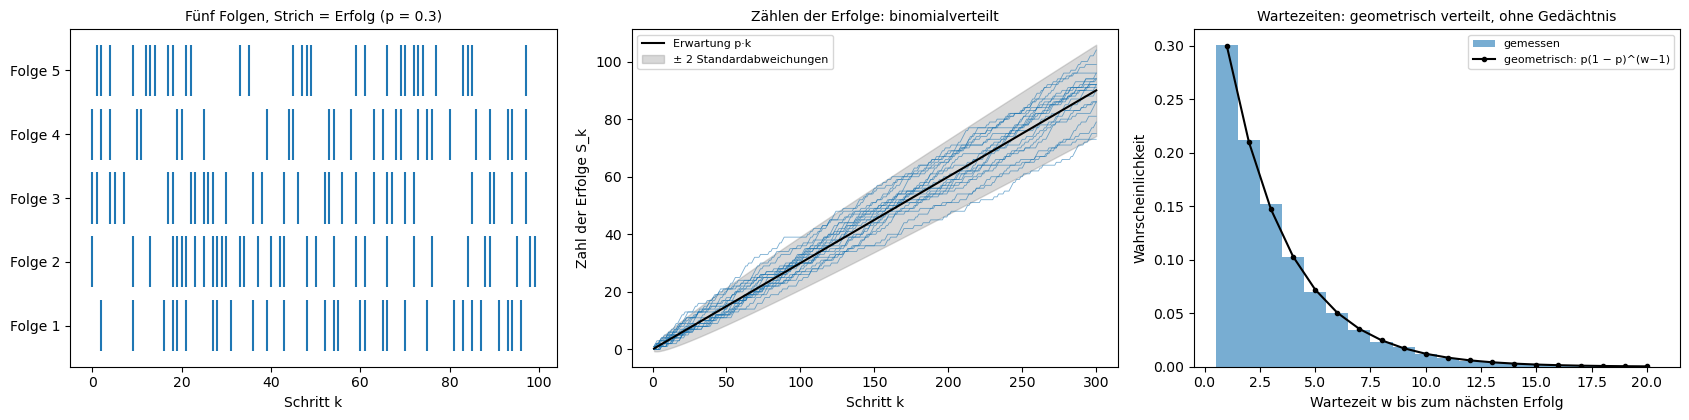

S_300: Mittel 90.10 (Theorie n·p = 90), Varianz 64.60 (Theorie n·p·(1−p) = 63)
Wartezeit: Mittel 3.315 (Theorie 1/p = 3.333), P(W > 5) = 0.165 (Theorie (1−p)^5 = 0.168)
Kein Gedächtnis: P(W > 3 + 2 | W > 3) = 0.489, P(W > 2) = 0.489 (Theorie beide (1−p)^2 = 0.490)


In [2]:
rng = np.random.default_rng(1)
p, n = 0.3, 300
X = rng.random((2000, n)) < p                                   # 2000 Folgen von je 300 Münzwürfen mit P(1) = p
S = np.cumsum(X, axis=1)                                         # Zahl der Erfolge bis zum Schritt k
waits = np.concatenate([np.diff(np.r_[-1, np.flatnonzero(row)]) for row in X[:200]])   # Wartezeiten bis zum nächsten Erfolg

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for r in range(5):
    axes[0].vlines(np.flatnonzero(X[r, :100]), r + 0.1, r + 0.9, lw=1.5)
axes[0].set_yticks(np.arange(5) + 0.5, [f"Folge {r + 1}" for r in range(5)])
axes[0].set_xlabel("Schritt k")
axes[0].set_title(f"Fünf Folgen, Strich = Erfolg (p = {p})", fontsize=10)
k = np.arange(1, n + 1)
for r in range(20):
    axes[1].plot(k, S[r], lw=0.6, c="tab:blue", alpha=0.6)
axes[1].plot(k, p * k, "k-", lw=1.5, label="Erwartung p·k")
axes[1].fill_between(k, p * k - 2 * np.sqrt(k * p * (1 - p)), p * k + 2 * np.sqrt(k * p * (1 - p)), color="grey", alpha=0.3, label="± 2 Standardabweichungen")
axes[1].set_xlabel("Schritt k")
axes[1].set_ylabel("Zahl der Erfolge S_k")
axes[1].set_title("Zählen der Erfolge: binomialverteilt", fontsize=10)
axes[1].legend(fontsize=8)
w = np.arange(1, 21)
axes[2].hist(waits, bins=np.arange(0.5, 21.5), density=True, alpha=0.6, label="gemessen")
axes[2].plot(w, p * (1 - p) ** (w - 1), "ko-", ms=3, label="geometrisch: p(1 − p)^(w−1)")
axes[2].set_xlabel("Wartezeit w bis zum nächsten Erfolg")
axes[2].set_ylabel("Wahrscheinlichkeit")
axes[2].set_title("Wartezeiten: geometrisch verteilt, ohne Gedächtnis", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"S_{n}: Mittel {S[:, -1].mean():.2f} (Theorie n·p = {n * p:.0f}), Varianz {S[:, -1].var():.2f} (Theorie n·p·(1−p) = {n * p * (1 - p):.0f})")
print(f"Wartezeit: Mittel {waits.mean():.3f} (Theorie 1/p = {1 / p:.3f}), P(W > 5) = {np.mean(waits > 5):.3f} (Theorie (1−p)^5 = {(1 - p) ** 5:.3f})")
long = waits[waits > 3]
print(f"Kein Gedächtnis: P(W > 3 + 2 | W > 3) = {np.mean(long > 5):.3f}, P(W > 2) = {np.mean(waits > 2):.3f} (Theorie beide (1−p)^2 = {(1 - p) ** 2:.3f})")

* Das **linke Bild** zeigt fünf Folgen, jeder Strich ist ein Erfolg. Die Striche liegen nicht gleichmäßig: Es gibt Häufungen und lange Lücken, obwohl jeder Versuch unabhängig ist. Solche Häufungen hält man leicht für ein Muster („Glückssträhne“), sie sind aber genau das, was reiner Zufall erzeugt. Das **mittlere Bild** zeigt die Zahl der Erfolge $S_k$: Sie wächst im Mittel wie $p\cdot k$ (schwarz), die Streuung um diese Gerade wächst wie $\sqrt k$ (graues Band).
* Das **rechte Bild** zeigt die Wartezeiten: Die Balken folgen der geometrischen Verteilung, am häufigsten ist Wartezeit 1, jede weitere Wartezeit ist um den Faktor $1 - p = 0.7$ seltener. Die **Ausgabe** bestätigt die Formeln: $S_{300}$ hat Mittel 90.10 und Varianz 64.60 (Theorie 90 und 63), die mittlere Wartezeit ist 3.315 (Theorie $1/p = 3.333$). Nach drei Fehlversuchen braucht man mit Wahrscheinlichkeit 0.489 noch mindestens zwei weitere, genau wie am Anfang (0.489, Theorie 0.490). Die Antwort auf die Vorhersage ist also nein: Der Prozess hat kein Gedächtnis, ein „fälliger“ Erfolg existiert nicht.
* **Wo er vorkommt:** überall, wo Ja/Nein-Ereignisse mit fester Wahrscheinlichkeit unabhängig aufeinander folgen: Bitfehler in einer Datenübertragung, defekte Teile in der Produktion, Klicks auf eine Anzeige (Konversionsraten in A/B-Tests), Treffer im Sport. Im maschinellen Lernen schaltet **Dropout** Neuronen nach einem Bernoulli-Prozess ab. Als Baustein steckt er im Random Walk (Exp. 2) und, mit kleinem $p$ in sehr kurzen Zeitschritten, im Poisson-Prozess (Exp. 5).

##### *2. Der Random Walk*

Wie weit entfernt sich ein Random Walk vom Start, und wie oft wechselt er die Seite? Vorher vorhersagen: Welcher Anteil der Zeit über null kommt am häufigsten vor, etwa 50 % oder Werte nahe 0 % und 100 %?

Simuliert werden 5000 Random Walks mit je 1000 Schritten $\pm1$. Links stehen sechs Pfade mit der Kurve $\pm\sqrt k$, in der Mitte das Histogramm der Endpunkte mit der Normalverteilung der Standardabweichung $\sqrt{1000}$, rechts das Histogramm des Zeitanteils über null mit der Arkussinus-Dichte. Die Ausgabe gibt die Streuung der Endpunkte, den Anteil der Pfade, die mehr als 90 % der Zeit auf einer Seite verbringen, und die mittlere Zahl der Rückkehren zum Start.

**Hintergrund & Fachbegriffe:**
- **Random Walk** (Irrfahrt): die Summe unabhängiger Zufallsschritte, hier $+1$ oder $-1$ mit Wahrscheinlichkeit je ½ (**symmetrisch**).
- **Diffusives Wachstum:** Die Varianzen der Schritte addieren sich zu $n$, also wächst der typische Abstand vom Start wie $\sqrt n$, nicht wie $n$.
- **Zentraler Grenzwertsatz:** Die Summe vieler unabhängiger Schritte ist annähernd normalverteilt.
- **Rückkehr:** ein Besuch des Startpunkts 0. Der Random Walk in einer Dimension kehrt sicher zurück (**rekurrent**), aber immer seltener.
- **Arkussinus-Gesetz:** Der Zeitanteil über null hat die U-förmige Dichte $1/(\pi\sqrt{u(1 - u)})$.

**Theorie:**

- **Mittelwert und Varianz:** Für $S_n = \xi_1 + \dots + \xi_n$ mit $\xi_k = \pm1$ hat jeder Schritt Mittelwert 0 und Varianz 1, also $\mathbb E[S_n] = 0$ und $\mathrm{Var}(S_n) = n$. Nach dem zentralen Grenzwertsatz ist $S_n/\sqrt n$ für großes $n$ standardnormalverteilt; nach dem Satz von Donsker (Abschnitt 3 der Theorie) wird der ganze gestauchte Pfad zur Brownschen Bewegung (Exp. 7).
- **Rekurrenz:** In einer und zwei Dimensionen kehrt der Random Walk mit Wahrscheinlichkeit 1 zum Start zurück, in drei und mehr Dimensionen nicht sicher (**transient**; in drei Dimensionen mit Wahrscheinlichkeit 0.34, Pólya 1921). In einer Dimension steht er nach $2k$ Schritten mit Wahrscheinlichkeit $\binom{2k}k2^{-2k}\approx1/\sqrt{\pi k}$ wieder am Start. Summiert über die ersten $n$ Schritte ergibt das im Mittel etwa $\sqrt{2n/\pi}$ Rückkehren: unendlich viele, aber immer seltener.
- **Arkussinus-Gesetz:** Der Anteil $u$ der Zeit über null hat die Dichte $1/(\pi\sqrt{u(1 - u)})$ und die Verteilungsfunktion $\tfrac2\pi\arcsin\sqrt u$. Daraus folgt zum Beispiel: Mit Wahrscheinlichkeit $\tfrac4\pi\arcsin\sqrt{0.1}\approx0.41$ ist ein Pfad mehr als 90 % der Zeit auf derselben Seite.
- **Einordnung:** Der Random Walk hat unabhängige und stationäre Zuwächse und ist ein Markov-Prozess und ein Martingal (Exp. 4), aber selbst nicht stationär, denn seine Varianz wächst.

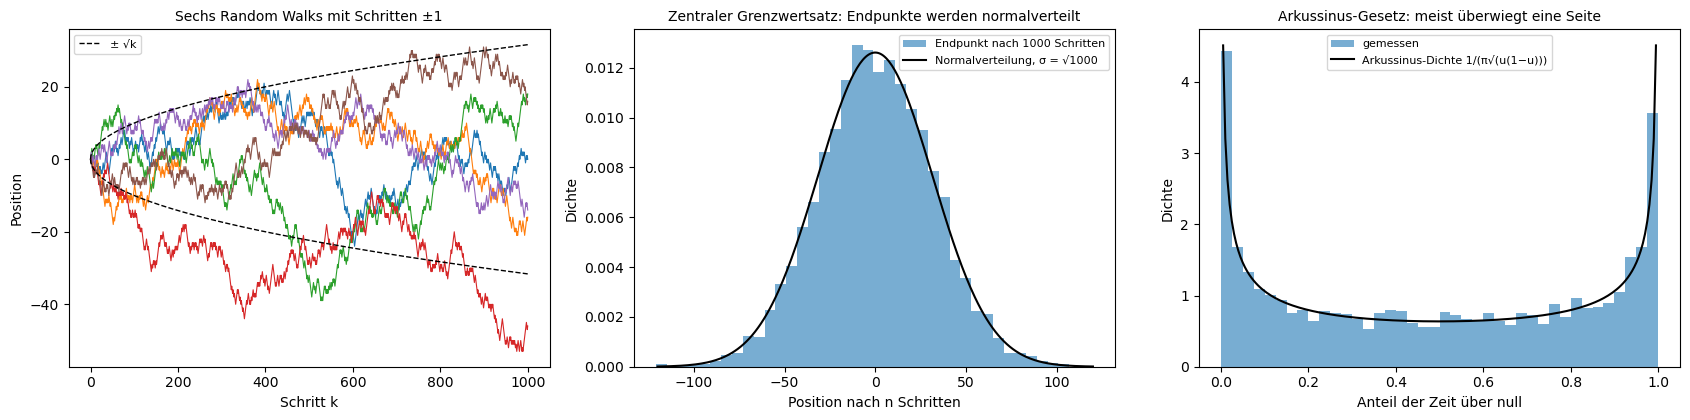

Endpunkt nach 1000 Schritten: Mittel 0.41, Standardabweichung 31.4 (Theorie √n = 31.6)
Pfade, die mehr als 90 % der Zeit auf einer Seite sind: 40.8% (Arkussinus: 41.0%); zwischen 45 % und 55 %: 6.5% (Arkussinus: 6.4%)
Rückkehren zum Start in 1000 Schritten: im Mittel 24.6 (Theorie ≈ √(2n/π) = 25.2)


In [3]:
rng = np.random.default_rng(2)
n, paths = 1000, 5000
steps = rng.choice([-1, 1], size=(paths, n))
walk = np.concatenate([np.zeros((paths, 1), dtype=int), np.cumsum(steps, axis=1)], axis=1)
frac_positive = np.mean(walk[:, 1:] > 0, axis=1)                 # Anteil der Zeit, den der Pfad über null verbringt
returns = np.sum(walk[:, 1:] == 0, axis=1)                       # Zahl der Rückkehren zum Start

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
k = np.arange(n + 1)
for r in range(6):
    axes[0].plot(k, walk[r], lw=0.8)
axes[0].plot(k, np.sqrt(k), "k--", lw=1, label="± √k")
axes[0].plot(k, -np.sqrt(k), "k--", lw=1)
axes[0].set_xlabel("Schritt k")
axes[0].set_ylabel("Position")
axes[0].set_title("Sechs Random Walks mit Schritten ±1", fontsize=10)
axes[0].legend(fontsize=8)
x = np.linspace(-120, 120, 300)
axes[1].hist(walk[:, -1], bins=np.arange(-121, 122, 6), density=True, alpha=0.6, label=f"Endpunkt nach {n} Schritten")
axes[1].plot(x, stats.norm.pdf(x, 0, np.sqrt(n)), "k-", label=f"Normalverteilung, σ = √{n}")
axes[1].set_xlabel("Position nach n Schritten")
axes[1].set_ylabel("Dichte")
axes[1].set_title("Zentraler Grenzwertsatz: Endpunkte werden normalverteilt", fontsize=10)
axes[1].legend(fontsize=8)
u = np.linspace(0.005, 0.995, 200)
axes[2].hist(frac_positive, bins=40, density=True, alpha=0.6, label="gemessen")
axes[2].plot(u, 1 / (np.pi * np.sqrt(u * (1 - u))), "k-", label="Arkussinus-Dichte 1/(π√(u(1−u)))")
axes[2].set_xlabel("Anteil der Zeit über null")
axes[2].set_ylabel("Dichte")
axes[2].set_title("Arkussinus-Gesetz: meist überwiegt eine Seite", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Endpunkt nach {n} Schritten: Mittel {walk[:, -1].mean():.2f}, Standardabweichung {walk[:, -1].std():.1f} (Theorie √n = {np.sqrt(n):.1f})")
edge = np.mean((frac_positive < 0.1) | (frac_positive > 0.9))
print(f"Pfade, die mehr als 90 % der Zeit auf einer Seite sind: {edge:.1%} (Arkussinus: {4 / np.pi * np.arcsin(np.sqrt(0.1)):.1%}); "
      f"zwischen 45 % und 55 %: {np.mean(np.abs(frac_positive - 0.5) < 0.05):.1%} (Arkussinus: {2 / np.pi * (np.arcsin(np.sqrt(0.55)) - np.arcsin(np.sqrt(0.45))):.1%})")
print(f"Rückkehren zum Start in {n} Schritten: im Mittel {returns.mean():.1f} (Theorie ≈ √(2n/π) = {np.sqrt(2 * n / np.pi):.1f})")

* Das **linke Bild** zeigt sechs Pfade, die sich in beide Richtungen vom Start entfernen. Die gestrichelte Kurve $\pm\sqrt k$ ist die typische Entfernung, einzelne Pfade gehen deutlich darüber hinaus. Das **mittlere Bild** zeigt: Die Endpunkte nach 1000 Schritten sind normalverteilt, mit Standardabweichung 31.4 (Theorie $\sqrt{1000} = 31.6$) und Mittel 0.41. Nach 1000 Schritten ist man also typischerweise nur etwa 30 Schritte vom Start entfernt.
* Das **rechte Bild** ist U-förmig wie die Arkussinus-Dichte: Am häufigsten sind Pfade, die fast immer über oder fast immer unter null bleiben. Laut **Ausgabe** verbringen 40.8 % der Pfade mehr als 90 % der Zeit auf einer Seite (Arkussinus 41.0 %), nur 6.5 % liegen zwischen 45 und 55 % (Arkussinus 6.4 %). Das ist die Antwort auf die Vorhersage. Rückkehren sind selten, im Mittel 24.6 in 1000 Schritten (Theorie $\sqrt{2n/\pi} = 25.2$). Wer bei einem fairen Münzspiel lange vorn liegt, hat deshalb keinen Grund anzunehmen, er sei besser: Lange Führungen sind der Normalfall.
* **Wo sie vorkommt:** als einfachstes Modell der **Diffusion** von Molekülen und Wärme, bei **Polymerketten** (ein Knäuel aus $N$ Gliedern hat einen Radius $\propto\sqrt N$), bei Kursen in der Finanzmathematik (Bachelier) und beim Kontostand eines fairen Spiels. **Random Walks auf Graphen** stecken in PageRank, in Suchverfahren auf Netzen und in Einbettungen von Knoten (DeepWalk, node2vec); Monte-Carlo-Verfahren bauen auf ihnen auf.

##### *3. Die Markov-Kette*

Wann vergisst eine Markov-Kette ihren Anfang, und welchen Anteil der Zeit verbringt sie in jedem Zustand? Vorher vorhersagen: Heute regnet es. Hängt die Wettervorhersage für in zehn Tagen noch spürbar davon ab?

Eine Wetterkette mit drei Zuständen Sonne, Wolken und Regen; die Übergangsmatrix $P$ steht in der Ausgabe (nach Sonne folgt zum Beispiel mit Wahrscheinlichkeit 0.7 wieder Sonne). Die stationäre Verteilung $\pi$ wird als linker Eigenvektor von $P$ berechnet. Links steht ein Pfad über 60 Tage, in der Mitte der Abstand der Verteilung nach $n$ Tagen zu $\pi$ für die drei möglichen Starts, mit der Vorhersage $\vert\lambda_2\vert^n$, rechts $\pi$ neben den Häufigkeiten in einem Pfad über 100 000 Tage. Die Ausgabe prüft außerdem die mittlere Dauer einer Regenphase.

**Hintergrund & Fachbegriffe:**
- **Übergangsmatrix:** $P_{ij}$ ist die Wahrscheinlichkeit, morgen in Zustand $j$ zu sein, wenn heute Zustand $i$ ist; jede Zeile summiert sich zu 1.
- **Stationäre Verteilung:** $\pi$ mit $\pi P = \pi$; ein **linker Eigenvektor** von $P$ zum Eigenwert 1 (ein gewöhnlicher Eigenvektor der transponierten Matrix $P^T$).
- **Totalvariationsabstand:** $\tfrac12\sum_i\vert\mu_i - \pi_i\vert$, der größte Unterschied der Wahrscheinlichkeit, den zwei Verteilungen einem Ereignis geben.
- **Zweiter Eigenwert** $\lambda_2$: bestimmt, wie schnell die Kette ihren Start vergisst, der Abstand fällt wie $\vert\lambda_2\vert^n$.
- **Ergodizität:** Der Zeitanteil in jedem Zustand eines langen Pfads ist gleich $\pi$.
- **Verweildauer:** Wie lange die Kette am Stück in einem Zustand bleibt; geometrisch verteilt mit Mittelwert $1/(1 - P_{ii})$.

**Theorie:**

- **Verteilung nach $n$ Schritten:** Ist $\mu$ die Verteilung heute (ein Zeilenvektor), ist $\mu P$ die von morgen und $\mu P^n$ die nach $n$ Tagen (**Chapman-Kolmogorov-Gleichung**).
- **Konvergenzsatz:** Eine Kette heißt **irreduzibel**, wenn jeder Zustand von jedem erreichbar ist, und **aperiodisch**, wenn sie nicht in einem festen Takt pendelt. Eine irreduzible, aperiodische Kette mit endlich vielen Zuständen hat genau eine stationäre Verteilung, und $\mu P^n\to\pi$ von jedem Start aus.
- **Warum $\vert\lambda_2\vert^n$:** Zerlegt man $\mu$ nach den Eigenvektoren von $P$, wird jeder Anteil bei jedem Schritt mit seinem Eigenwert multipliziert. Der Anteil zum Eigenwert 1 ist $\pi$ und bleibt; alle anderen schrumpfen, der langsamste wie $\vert\lambda_2\vert^n$. Die **Spektrallücke** $1 - \vert\lambda_2\vert$ misst also, wie schnell die Kette mischt; $1/(1 - \vert\lambda_2\vert)$ heißt **Relaxationszeit** und ist ein grobes Maß dafür, nach wie vielen Schritten die Kette ihren Anfang vergessen hat.
- **Ergodensatz:** Der Zeitanteil in Zustand $i$ strebt mit Wahrscheinlichkeit 1 gegen $\pi_i$, und die mittlere Zeit bis zur Rückkehr nach $i$ ist $1/\pi_i$ (Satz von Kac).
- **Verweildauer:** In jedem Schritt verlässt die Kette Zustand $i$ mit Wahrscheinlichkeit $1 - P_{ii}$, unabhängig von der Vergangenheit; die Verweildauer ist deshalb geometrisch verteilt (Exp. 1) mit Mittelwert $1/(1 - P_{ii})$.

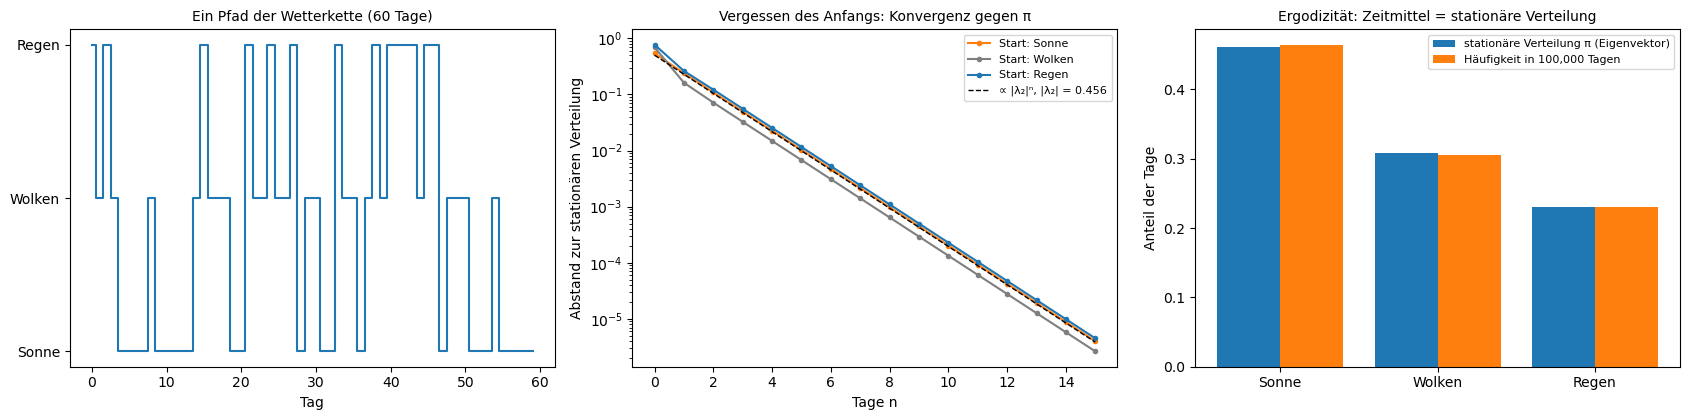

Übergangsmatrix P (Zeilen: heute, Spalten: morgen):
[[0.7 0.2 0.1]
 [0.3 0.4 0.3]
 [0.2 0.4 0.4]]
Eigenwerte von P: [1.     0.4562 0.0438]
Stationäre Verteilung π = [0.4615 0.3077 0.2308]  (Sonne, Wolken, Regen)
Häufigkeiten im Pfad     = [0.4635 0.3056 0.2309]
Mittlere Dauer einer Regenphase: gemessen 1.67 Tage, Theorie 1/(1 − P_RR) = 1.67


In [4]:
rng = np.random.default_rng(3)
names = ["Sonne", "Wolken", "Regen"]
P = np.array([[0.7, 0.2, 0.1],
              [0.3, 0.4, 0.3],
              [0.2, 0.4, 0.4]])                                  # P[i, j] = Wahrscheinlichkeit für j morgen, wenn heute i
evals, evecs = np.linalg.eig(P.T)
order = np.argsort(-np.abs(evals))
pi = np.real(evecs[:, order[0]]); pi /= pi.sum()                 # stationäre Verteilung: linker Eigenvektor zum Eigenwert 1
lam2 = np.abs(evals[order[1]])

T = 100_000
path = np.empty(T, dtype=int); path[0] = 2
cum = np.cumsum(P, axis=1)
u = rng.random(T)
for t in range(1, T):
    path[t] = np.searchsorted(cum[path[t - 1]], u[t])
freq = np.bincount(path, minlength=3) / T

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].step(np.arange(60), path[:60], where="mid", c="tab:blue")
axes[0].set_yticks([0, 1, 2], names)
axes[0].set_xlabel("Tag")
axes[0].set_title("Ein Pfad der Wetterkette (60 Tage)", fontsize=10)
ns = np.arange(16)
for start, c in zip(range(3), ["tab:orange", "tab:grey", "tab:blue"]):
    mu = np.eye(3)[start]
    tv = []
    for _ in ns:
        tv.append(0.5 * np.abs(mu - pi).sum())
        mu = mu @ P
    axes[1].semilogy(ns, tv, "o-", ms=3, c=c, label=f"Start: {names[start]}")
axes[1].semilogy(ns, 0.5 * lam2 ** ns, "k--", lw=1, label=f"∝ |λ₂|ⁿ, |λ₂| = {lam2:.3f}")
axes[1].set_xlabel("Tage n")
axes[1].set_ylabel("Abstand zur stationären Verteilung")
axes[1].set_title("Vergessen des Anfangs: Konvergenz gegen π", fontsize=10)
axes[1].legend(fontsize=8)
xb = np.arange(3)
axes[2].bar(xb - 0.2, pi, 0.4, label="stationäre Verteilung π (Eigenvektor)")
axes[2].bar(xb + 0.2, freq, 0.4, label=f"Häufigkeit in {T:,} Tagen")
axes[2].set_xticks(xb, names)
axes[2].set_ylabel("Anteil der Tage")
axes[2].set_title("Ergodizität: Zeitmittel = stationäre Verteilung", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Übergangsmatrix P (Zeilen: heute, Spalten: morgen):")
print(P)
print(f"Eigenwerte von P: {np.round(evals[order], 4)}")
print(f"Stationäre Verteilung π = {np.round(pi, 4)}  (Sonne, Wolken, Regen)")
print(f"Häufigkeiten im Pfad     = {np.round(freq, 4)}")
rain = np.r_[0, (path == 2).astype(int), 0]
run_lengths = np.flatnonzero(np.diff(rain) == -1) - np.flatnonzero(np.diff(rain) == 1)
print(f"Mittlere Dauer einer Regenphase: gemessen {run_lengths.mean():.2f} Tage, Theorie 1/(1 − P_RR) = {1 / (1 - P[2, 2]):.2f}")

* Das **linke Bild** zeigt einen Pfad: Sonnenphasen dauern länger als Regenphasen, weil $P_{\text{Sonne, Sonne}} = 0.7$ größer ist als $P_{\text{Regen, Regen}} = 0.4$. Das **mittlere Bild** hat eine logarithmische y-Achse: Der Abstand zur stationären Verteilung fällt für jeden Start auf einer Geraden, also exponentiell, parallel zu $0.456^n$. Nach zehn Tagen ist er kleiner als $10^{-3}$. Die Antwort auf die Vorhersage: Der heutige Regen ist nach zehn Tagen praktisch vergessen, die Vorhersage ist dann einfach die stationäre Verteilung.
* Das **rechte Bild** zeigt, dass die stationäre Verteilung und die Häufigkeiten im langen Pfad übereinstimmen. Die **Ausgabe**: Eigenwerte 1, 0.4562 und 0.0438; $\pi = (0.4615, 0.3077, 0.2308)$, das sind genau $6/13, 4/13, 3/13$; gemessen $(0.4635, 0.3056, 0.2309)$. Regenphasen dauern im Mittel 1.67 Tage, wie $1/(1 - 0.4)$.
* **Wo sie vorkommt:** **PageRank** ist die stationäre Verteilung eines zufälligen Surfers auf dem Web-Graphen. **MCMC-Verfahren** (Markov Chain Monte Carlo) bauen eine Kette, deren stationäre Verteilung die gesuchte Verteilung ist, etwa die A-posteriori-Verteilung in der Bayes-Statistik. **Hidden-Markov-Modelle** dienen der Spracherkennung und Genomanalyse, **Markov-Entscheidungsprozesse** sind das Grundmodell des Reinforcement Learning. Weitere Beispiele: n-Gramm-Sprachmodelle, Warteschlangen, Übergänge zwischen Kreditratings, Bonus-Malus-Systeme in der Versicherung.

##### *4. Martingale: faire Spiele und Stoppzeiten*

Kann man ein faires Spiel durch geschicktes Aufhören gewinnen? Vorher vorhersagen: Ein Spieler setzt bei jedem Münzwurf 1 Euro und hört auf, sobald er 5 Euro gewonnen oder 10 Euro verloren hat. Mit welcher Wahrscheinlichkeit geht er mit Gewinn nach Hause?

Untersucht werden zwei Stoppregeln. Erstens der gestoppte Random Walk (Ruin des Spielers): Für sechs Paare $(a, b)$ werden je 4000 Spiele bis $+a$ oder $-b$ gespielt. Links stehen acht Spiele mit $a = 5$, $b = 10$, in der Mitte die gemessenen Wahrscheinlichkeiten für $+a$ gegen die Vorhersage $b/(a + b)$ aus dem Stoppsatz. Zweitens die Verdopplungsstrategie mit Kapital 1023 für 100 000 Spieler; rechts steht die Verteilung der Gewinne (logarithmische y-Achse). Die Ausgabe gibt außerdem die mittleren Gewinne und Spieldauern.

**Hintergrund & Fachbegriffe:**
- **Martingal:** ein faires Spiel; der erwartete Stand nach der nächsten Runde ist der heutige. Der Name kommt von der Verdopplungsstrategie, die im Französischen „la martingale“ hieß.
- **Stoppzeit:** eine Regel, wann man aufhört, die nur benutzt, was bisher geschehen ist („bei +5 aufhören“).
- **Optionaler Stoppsatz:** Für ein Martingal und eine Stoppzeit mit beschränktem Spielstand gilt $\mathbb E[X_\tau] = X_0$; der erwartete Gewinn bleibt 0.
- **Ruin des Spielers:** Aus dem Stoppsatz folgt $P(+a) = b/(a + b)$, und die mittlere Spieldauer ist $a\cdot b$.
- **Verdopplungsstrategie:** nach jedem Verlust den Einsatz verdoppeln, nach dem ersten Gewinn aufhören. Mit Kapital $2^{10} - 1 = 1023$ kann man zehnmal hintereinander verlieren.
- **Standardfehler:** die typische Abweichung eines Mittelwerts aus $N$ Werten vom wahren Erwartungswert, Standardabweichung$/\sqrt N$.

**Theorie:**

- **Zwei Martingale:** Der symmetrische Random Walk $S_n$ ist ein Martingal, und ebenso $S_n^2 - n$, denn $\mathbb E[S_{n+1}^2\mid S_n] = S_n^2 + 1$. Bei $\geq$ statt $=$ spricht man von einem **Submartingal** (günstiges Spiel), bei $\leq$ von einem **Supermartingal** (ungünstiges Spiel, etwa jedes Spiel im Kasino).
- **Optionaler Stoppsatz** (Doob): Ist $X$ ein Martingal und $\tau$ eine Stoppzeit, gilt $\mathbb E[X_\tau] = X_0$, sofern $\tau$ beschränkt ist oder $X$ bis $\tau$ beschränkt bleibt (oder ähnliche Bedingungen gelten). Keine Regel, wann man aufhört, macht ein faires Spiel günstig.
- **Ruin des Spielers:** Aus $\mathbb E[S_\tau] = 0$ folgt $a\,P(+a) - b\,(1 - P(+a)) = 0$, also $P(+a) = b/(a + b)$. Aus $\mathbb E[S_\tau^2 - \tau] = 0$ folgt $\mathbb E[\tau] = \mathbb E[S_\tau^2] = a^2\frac b{a + b} + b^2\frac a{a + b} = ab$.
- **Verdopplungsstrategie:** Mit unbegrenztem Kapital gewinnt man sicher 1, weil der erste Gewinn alle Verluste ausgleicht. Das widerspricht dem Stoppsatz nicht, weil der Kontostand vor dem Stopp unbeschränkt nach unten gehen darf. Mit Kapital $2^k - 1$ gewinnt man mit Wahrscheinlichkeit $1 - 2^{-k}$ einen Euro und verliert mit Wahrscheinlichkeit $2^{-k}$ alles; der Erwartungswert ist $(1 - 2^{-k}) - (2^k - 1)\,2^{-k} = 0$.
- **Martingal-Konvergenzsatz:** Ein Martingal, bei dem $\mathbb E\vert X_t\vert$ beschränkt bleibt, konvergiert mit Wahrscheinlichkeit 1. Ein Beispiel ist $Z_n/m^n$ beim Verzweigungsprozess (Exp. 14).

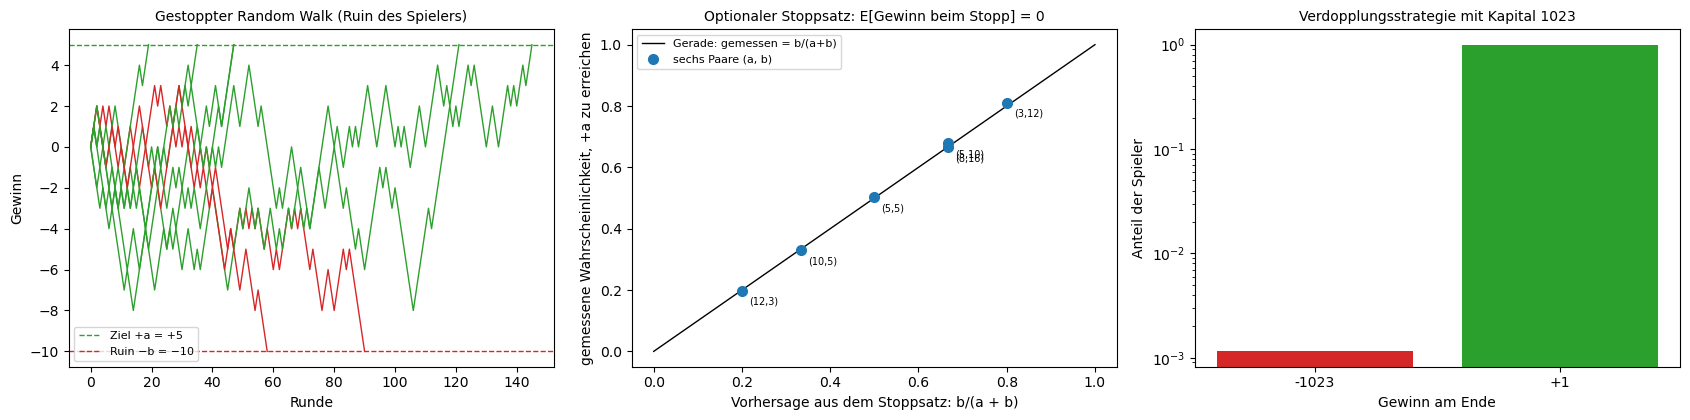

a =  5, b =  5:  P(+a) = 0.502 (b/(a+b) = 0.500),  mittlerer Gewinn +0.025 (0),  mittlere Dauer   25.1 (a·b = 25)
a =  5, b = 10:  P(+a) = 0.678 (b/(a+b) = 0.667),  mittlerer Gewinn +0.170 (0),  mittlere Dauer   49.2 (a·b = 50)
a = 10, b =  5:  P(+a) = 0.330 (b/(a+b) = 0.333),  mittlerer Gewinn -0.054 (0),  mittlere Dauer   49.9 (a·b = 50)
a =  3, b = 12:  P(+a) = 0.811 (b/(a+b) = 0.800),  mittlerer Gewinn +0.169 (0),  mittlere Dauer   36.2 (a·b = 36)
a = 12, b =  3:  P(+a) = 0.198 (b/(a+b) = 0.200),  mittlerer Gewinn -0.030 (0),  mittlere Dauer   35.9 (a·b = 36)
a =  8, b = 16:  P(+a) = 0.666 (b/(a+b) = 0.667),  mittlerer Gewinn -0.016 (0),  mittlere Dauer  129.2 (a·b = 128)
Verdopplungsstrategie: Anteil mit Gewinn +1: 0.9989 (Theorie 1 − 2^−10 = 0.9990), Anteil pleite (−1023): 0.0011, mittlerer Gewinn -0.178 (Theorie 0)


In [5]:
rng = np.random.default_rng(4)

def ruin(a, b, n_games, rng, max_steps=20_000):
    """Symmetrischer Random Walk ab 0, gestoppt bei +a oder -b. Gibt Endpunkte und Spieldauern zurück."""
    pos = np.zeros(n_games, dtype=int); dur = np.zeros(n_games, dtype=int); alive = np.ones(n_games, dtype=bool)
    for t in range(1, max_steps + 1):
        pos[alive] += rng.choice([-1, 1], size=alive.sum())
        dur[alive] = t
        alive &= (pos < a) & (pos > -b)
        if not alive.any():
            break
    return pos, dur

cases = [(5, 5), (5, 10), (10, 5), (3, 12), (12, 3), (8, 16)]
results = [(a, b) + tuple(ruin(a, b, 4000, rng)) for a, b in cases]

def doubling(n_players, bankroll, max_rounds, rng):
    """Verdopplungsstrategie: Einsatz 1, nach jedem Verlust verdoppeln, nach einem Gewinn aufhören (fairer Münzwurf)."""
    final = np.empty(n_players)
    for i in range(n_players):
        money, stake = bankroll, 1
        for _ in range(max_rounds):
            if stake > money:                                    # Einsatz nicht mehr bezahlbar: Spieler ist pleite
                break
            if rng.random() < 0.5:
                money += stake
                break
            money -= stake
            stake *= 2
        final[i] = money - bankroll
    return final

gain = doubling(100_000, bankroll=1023, max_rounds=50, rng=rng)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
rng_demo = np.random.default_rng(40)
for r in range(8):
    w = [0]
    while -10 < w[-1] < 5:
        w.append(w[-1] + rng_demo.choice([-1, 1]))
    axes[0].plot(w, lw=1, c="tab:green" if w[-1] == 5 else "tab:red")
axes[0].axhline(5, color="tab:green", ls="--", lw=1, label="Ziel +a = +5")
axes[0].axhline(-10, color="tab:red", ls="--", lw=1, label="Ruin −b = −10")
axes[0].set_xlabel("Runde")
axes[0].set_ylabel("Gewinn")
axes[0].set_title("Gestoppter Random Walk (Ruin des Spielers)", fontsize=10)
axes[0].legend(fontsize=8)
theory = [b / (a + b) for a, b, *_ in results]
measured = [np.mean(pos == a) for a, b, pos, dur in results]
axes[1].plot([0, 1], [0, 1], "k-", lw=1, label="Gerade: gemessen = b/(a+b)")
axes[1].plot(theory, measured, "o", ms=7, label="sechs Paare (a, b)")
for (a, b, *_), x, y in zip(results, theory, measured):
    axes[1].annotate(f"({a},{b})", (x, y), textcoords="offset points", xytext=(5, -10), fontsize=7)
axes[1].set_xlabel("Vorhersage aus dem Stoppsatz: b/(a + b)")
axes[1].set_ylabel("gemessene Wahrscheinlichkeit, +a zu erreichen")
axes[1].set_title("Optionaler Stoppsatz: E[Gewinn beim Stopp] = 0", fontsize=10)
axes[1].legend(fontsize=8)
vals, counts = np.unique(gain, return_counts=True)
axes[2].bar(range(len(vals)), counts / len(gain), color=["tab:red" if v < 0 else "tab:green" for v in vals])
axes[2].set_xticks(range(len(vals)), [f"{v:+.0f}" for v in vals])
axes[2].set_yscale("log")
axes[2].set_xlabel("Gewinn am Ende")
axes[2].set_ylabel("Anteil der Spieler")
axes[2].set_title("Verdopplungsstrategie mit Kapital 1023", fontsize=10)
plt.tight_layout()
plt.show()

for a, b, pos, dur in results:
    print(f"a = {a:2d}, b = {b:2d}:  P(+a) = {np.mean(pos == a):.3f} (b/(a+b) = {b / (a + b):.3f}),  "
          f"mittlerer Gewinn {pos.mean():+.3f} (0),  mittlere Dauer {dur.mean():6.1f} (a·b = {a * b})")
print(f"Verdopplungsstrategie: Anteil mit Gewinn +1: {np.mean(gain == 1):.4f} (Theorie 1 − 2^−10 = {1 - 2 ** -10:.4f}), "
      f"Anteil pleite (−1023): {np.mean(gain == -1023):.4f}, mittlerer Gewinn {gain.mean():+.3f} (Theorie 0)")

* Im **linken Bild** erreichen die grünen Pfade das Ziel $+5$, die roten den Ruin bei $-10$. Die meisten werden grün, und das ist die Antwort auf die Vorhersage: $P(+5) = 10/15 = 2/3$. Die seltenen Verluste sind aber doppelt so groß wie die Gewinne, sodass der erwartete Gewinn $\tfrac23\cdot5 - \tfrac13\cdot10 = 0$ bleibt. Im **mittleren Bild** liegen alle sechs Paare auf der Geraden: gemessen 0.502, 0.678, 0.330, 0.811, 0.198, 0.666 gegen 0.500, 0.667, 0.333, 0.800, 0.200, 0.667. Die mittleren Spieldauern laut **Ausgabe** sind 25.1, 49.2, 49.9, 36.2, 35.9 und 129.2 Runden gegen $a\cdot b = 25, 50, 50, 36, 36, 128$; die mittleren Gewinne liegen alle innerhalb von $\pm0.2$ um 0.
* Das **rechte Bild** zeigt die Verdopplungsstrategie: 99.89 % der Spieler gewinnen 1 Euro (Theorie $1 - 2^{-10} = 99.90\,\%$), 0.11 % verlieren alle 1023 Euro. Der mittlere Gewinn $-0.178$ ist mit 0 verträglich: Weil ein Verlust von 1023 so schwer wiegt, hat der Mittelwert über 100 000 Spieler einen Standardfehler von etwa 0.1. Die Strategie verwandelt viele kleine Gewinne in einen seltenen großen Verlust, ohne den Erwartungswert zu ändern.
* **Wo sie vorkommen:** In der **Finanzmathematik** ist ein arbitragefreier Preis ein Martingal unter dem **risikoneutralen Maß**; darauf beruht die Bewertung von Optionen. **Sequentielle Tests** (Wald) und moderne A/B-Tests, die man jederzeit auswerten darf, benutzen Test-Martingale, damit frühes Stoppen das Ergebnis nicht verfälscht. In der **Lerntheorie** liefern Martingal-Ungleichungen (Azuma-Hoeffding) Garantien für Lernverfahren. Die Folge der Bayes-Schätzungen bei wachsender Datenmenge ist ein Martingal; und im Kasino sind alle Spiele Supermartingale, sodass keine Stoppregel hilft.

##### *5. Der Poisson-Prozess*

Wie verteilen sich zufällige Ereignisse in der Zeit, wenn sie unabhängig voneinander mit fester Rate eintreten? Vorher vorhersagen: Ein Bus kommt im Mittel alle 30 Minuten, aber rein zufällig (Poisson-Prozess). Man kommt zu einem beliebigen Zeitpunkt an die Haltestelle. Wie lange wartet man im Mittel?

Simuliert werden 20 000 Pfade eines Poisson-Prozesses mit Rate $\lambda = 2$ bis $T = 10$, gebaut aus exponentialverteilten Wartezeiten. Links stehen sechs Zählpfade $N(t)$ mit der Erwartung $\lambda t$, in der Mitte die Wartezeiten mit der Exponentialdichte, rechts die Verteilung von $N(10)$ mit der Poisson-Verteilung. Die Ausgabe prüft Mittelwert und Varianz der Zählung, die mittlere Wartezeit und die Restwartezeit von Wartenden, die schon 0.5 Zeiteinheiten gewartet haben.

**Hintergrund & Fachbegriffe:**
- **Zählprozess:** $N(t)$ zählt die Ereignisse bis zur Zeit $t$; ein Pfad ist eine Treppe mit Stufen der Höhe 1.
- **Rate** $\lambda$: die mittlere Zahl der Ereignisse pro Zeiteinheit.
- **Exponentialverteilung:** Dichte $\lambda e^{-\lambda t}$, Mittelwert $1/\lambda$, gedächtnislos.
- **Poisson-Verteilung:** $P(N = k) = e^{-\lambda T}(\lambda T)^k/k!$, Mittelwert und Varianz $\lambda T$.
- **Fano-Faktor:** Varianz durch Mittelwert der Zählung; 1 beim Poisson-Prozess.
- **Restwartezeit:** die Zeit, die man ab einem bestimmten Moment noch bis zum nächsten Ereignis wartet.

**Theorie:**

- **Drei gleichwertige Beschreibungen:** (1) Die Zuwächse sind unabhängig und stationär, und $N(t)$ ist Poisson-verteilt mit Mittelwert $\lambda t$. (2) Die Wartezeiten zwischen den Ereignissen sind unabhängig und exponentialverteilt mit Mittelwert $1/\lambda$. (3) Grenzfall des Bernoulli-Prozesses mit $p = \lambda\,\Delta t$ und $\Delta t\to0$ (Exp. 1). Im Code wird (2) benutzt.
- **Fano-Faktor:** Werte über 1 zeigen gebündelte Ereignisse (Cluster), Werte unter 1 regelmäßigere Ereignisse als beim Poisson-Prozess (Variation 3).
- **Wartezeit-Paradoxon:** Kommt man zu einem zufälligen Zeitpunkt, landet man mit größerer Wahrscheinlichkeit in einer langen Lücke als in einer kurzen, weil lange Lücken mehr Zeit abdecken. Die Lücke, in die man fällt, ist im Mittel $2/\lambda$ lang, doppelt so lang wie eine typische; davon liegt im Mittel die Hälfte vor und die Hälfte nach der Ankunft.
- **Überlagerung und Ausdünnung:** Zwei unabhängige Poisson-Prozesse zusammen ergeben einen mit Rate $\lambda_1 + \lambda_2$; behält man jedes Ereignis mit Wahrscheinlichkeit $q$, bleibt einer mit Rate $q\lambda$.
- **Varianten:** Beim **zusammengesetzten Poisson-Prozess** springt der Wert bei jedem Ereignis um eine zufällige Höhe (Schadenssummen einer Versicherung, Exp. 12); beim **inhomogenen** hängt die Rate $\lambda(t)$ von der Zeit ab (Kundenaufkommen über den Tag). Der kompensierte Prozess $N(t) - \lambda t$ ist ein Martingal.

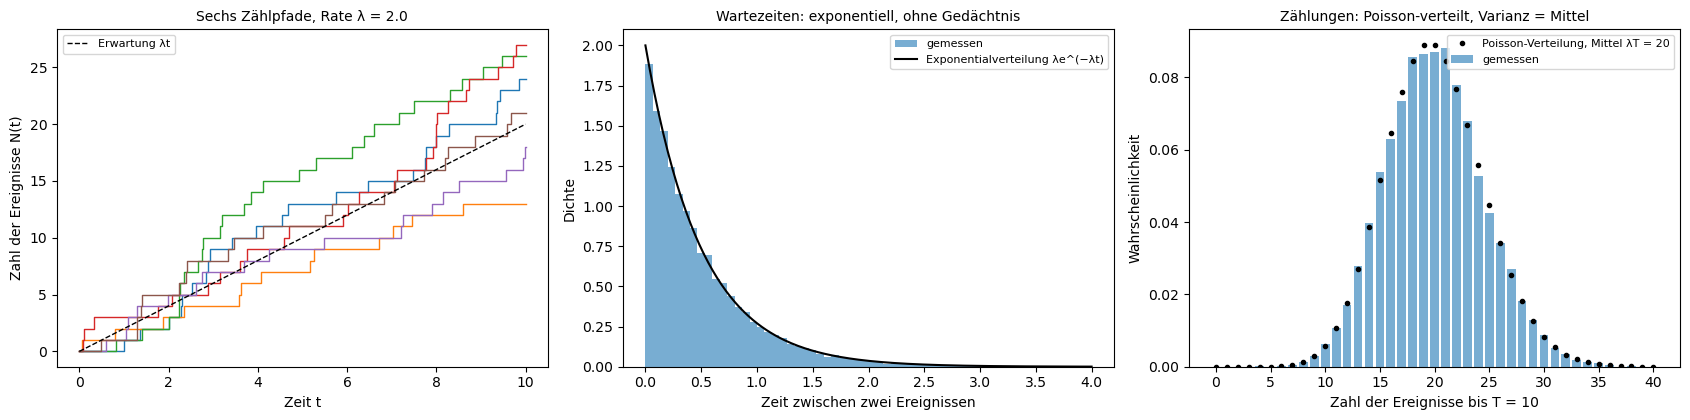

N(T): Mittel 19.995, Varianz 20.252 (Theorie beide λT = 20); Fano-Faktor 1.013
Wartezeit: Mittel 0.5004 (Theorie 1/λ = 0.5)
Kein Gedächtnis: mittlere Restwartezeit nach 0.5 Wartezeit 0.4923 (wieder 1/λ = 0.5)


In [6]:
rng = np.random.default_rng(5)
lam, T = 2.0, 10.0
gaps = rng.exponential(1 / lam, size=(20_000, 60))                # Wartezeiten zwischen den Ereignissen
times = np.cumsum(gaps, axis=1)
counts = (times <= T).sum(axis=1)                                # Zahl der Ereignisse bis T

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for r in range(6):
    ev = times[r][times[r] <= T]
    axes[0].step(np.r_[0, ev, T], np.r_[0, np.arange(1, len(ev) + 1), len(ev)], where="post", lw=1)
axes[0].plot([0, T], [0, lam * T], "k--", lw=1, label="Erwartung λt")
axes[0].set_xlabel("Zeit t")
axes[0].set_ylabel("Zahl der Ereignisse N(t)")
axes[0].set_title(f"Sechs Zählpfade, Rate λ = {lam}", fontsize=10)
axes[0].legend(fontsize=8)
x = np.linspace(0, 4, 200)
axes[1].hist(gaps[:, 0], bins=60, range=(0, 4), density=True, alpha=0.6, label="gemessen")
axes[1].plot(x, lam * np.exp(-lam * x), "k-", label="Exponentialverteilung λe^(−λt)")
axes[1].set_xlabel("Zeit zwischen zwei Ereignissen")
axes[1].set_ylabel("Dichte")
axes[1].set_title("Wartezeiten: exponentiell, ohne Gedächtnis", fontsize=10)
axes[1].legend(fontsize=8)
kk = np.arange(0, 41)
axes[2].bar(kk, np.bincount(counts, minlength=41)[:41] / len(counts), alpha=0.6, label="gemessen")
axes[2].plot(kk, stats.poisson.pmf(kk, lam * T), "ko", ms=3, label=f"Poisson-Verteilung, Mittel λT = {lam * T:.0f}")
axes[2].set_xlabel(f"Zahl der Ereignisse bis T = {T:.0f}")
axes[2].set_ylabel("Wahrscheinlichkeit")
axes[2].set_title("Zählungen: Poisson-verteilt, Varianz = Mittel", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"N(T): Mittel {counts.mean():.3f}, Varianz {counts.var():.3f} (Theorie beide λT = {lam * T:.0f}); Fano-Faktor {counts.var() / counts.mean():.3f}")
print(f"Wartezeit: Mittel {gaps.mean():.4f} (Theorie 1/λ = {1 / lam})")
cond = gaps[:, 0][gaps[:, 0] > 0.5] - 0.5
print(f"Kein Gedächtnis: mittlere Restwartezeit nach 0.5 Wartezeit {cond.mean():.4f} (wieder 1/λ = {1 / lam})")

* Das **linke Bild** zeigt Treppen, die in unregelmäßigen Abständen um 1 springen und im Mittel der Geraden $2t$ folgen. Das **mittlere Bild** zeigt die Wartezeiten: Kurze sind am häufigsten, die Dichte fällt exponentiell. Das **rechte Bild** zeigt die Zählungen bis $T = 10$, Poisson-verteilt um 20.
* Die **Ausgabe**: $N(10)$ hat Mittel 19.995 und Varianz 20.252, der Fano-Faktor ist 1.013 (Theorie 1). Die mittlere Wartezeit ist 0.5004 (Theorie $1/\lambda = 0.5$). Wer schon 0.5 gewartet hat, wartet im Mittel noch 0.4923, also so lange wie ganz am Anfang. Das beantwortet die Bus-Frage: Bei rein zufällig fahrenden Bussen wartet man im Mittel die vollen 30 Minuten, nicht 15 (**Wartezeit-Paradoxon**). Der Grund: Man kommt mit größerer Wahrscheinlichkeit während einer langen Lücke an als während einer kurzen.
* **Wo er vorkommt:** radioaktiver Zerfall (Klicks eines Geigerzählers), Photonen bei schwachem Licht (**Schrotrauschen** in Kameras und Detektoren), Anrufe in einem Callcenter und Anfragen an einen Server (**Warteschlangentheorie**, Kapazitätsplanung), Schadensfälle einer Versicherung (Cramér-Lundberg-Modell), Mutationen entlang eines Stammbaums, Aktionspotenziale von Neuronen in erster Näherung. Mit zeitabhängiger Rate (inhomogen) oder Selbstanregung (Hawkes-Prozess) beschreibt er Kundenaufkommen über den Tag, Nachbeben und Transaktionen an der Börse. Er liefert auch die Sprünge der Lévy-Prozesse (Exp. 12).

##### *6. Weißes Rauschen*

Woran erkennt man weißes Rauschen, und was unterscheidet es von korreliertem (farbigem) Rauschen? Vorher vorhersagen: Das farbige Rauschen hat dieselbe Varianz 1 wie das weiße. Bei welchen Frequenzen hat es mehr Leistung, bei welchen weniger?

Verglichen werden $2^{16}$ Werte Gaußsches weißes Rauschen ($\sigma = 1$) und ebenso viele Werte eines Ornstein-Uhlenbeck-Prozesses mit $\theta = 0.05$, dessen Rauschen so gewählt ist, dass die Varianz ebenfalls 1 ist; seine Werte bleiben etwa 20 Schritte lang korreliert. Links stehen 300 Werte beider Signale, in der Mitte ihre Autokorrelation bis zur Verschiebung 40, rechts ihre Leistungsspektren (Welch-Verfahren, doppelt logarithmisch).

**Hintergrund & Fachbegriffe:**
- **Autokorrelation** $\rho(\tau)$: die Korrelation eines Signals mit sich selbst, um $\tau$ Schritte verschoben.
- **Leistungsspektrum** (PSD): wie sich die Varianz auf die Frequenzen verteilt; die Fläche darunter ist die Varianz. Nach **Wiener-Chintschin** ist es die Fourier-Transformierte der Autokovarianz.
- **Weiß:** flaches Spektrum, alle Frequenzen gleich stark; bei Abtastrate $f_s = 1$ ist die Höhe $2\sigma^2/f_s = 2$.
- **Farbiges Rauschen:** Rauschen mit Frequenzabhängigkeit, hier mit mehr Leistung bei tiefen Frequenzen.
- **Welch-Verfahren:** Spektrum aus dem Mittel über viele überlappende Stücke des Signals; einzelne Stücke wären sehr verrauscht.
- **Nyquist-Frequenz:** die höchste Frequenz, die man bei Abtastrate $f_s$ sehen kann, $f_s/2 = 0.5$.

**Theorie:**

- **Definition:** Weißes Rauschen in diskreter Zeit ist eine Folge unkorrelierter Werte mit Mittelwert 0 und Varianz $\sigma^2$, meist unabhängig und normalverteilt (**Gaußsches weißes Rauschen**). Seine Autokorrelation ist $\rho(0) = 1$ und $\rho(\tau) = 0$ für $\tau\neq0$.
- **Warum flach:** Nach Wiener-Chintschin ist das Spektrum die Fourier-Transformierte der Autokovarianz. Die Fourier-Transformierte eines einzelnen Strichs bei $\tau = 0$ ist eine Konstante. Bei Abtastrate $f_s$ ist das einseitige Spektrum $2\sigma^2/f_s$ zwischen 0 und $f_s/2$; die Fläche darunter ist $2\sigma^2/f_s\cdot f_s/2 = \sigma^2$, die Varianz.
- **Farben:** Korrelierte Werte verschieben Leistung zu tiefen Frequenzen. **Rosa Rauschen** hat ein Spektrum $\propto1/f$, **braunes Rauschen** (die Brownsche Bewegung) $\propto1/f^2$; der Ornstein-Uhlenbeck-Prozess ist bei tiefen Frequenzen weiß und bei hohen braun (Exp. 10).
- **Stetige Zeit:** Dort ist weißes Rauschen keine Funktion, sondern die formale Ableitung $\mathrm dW/\mathrm dt$ der Brownschen Bewegung, mit unendlicher Varianz. Man benutzt es nur in Integralen, etwa in stochastischen Differentialgleichungen (Abschnitt 4 der Theorie).

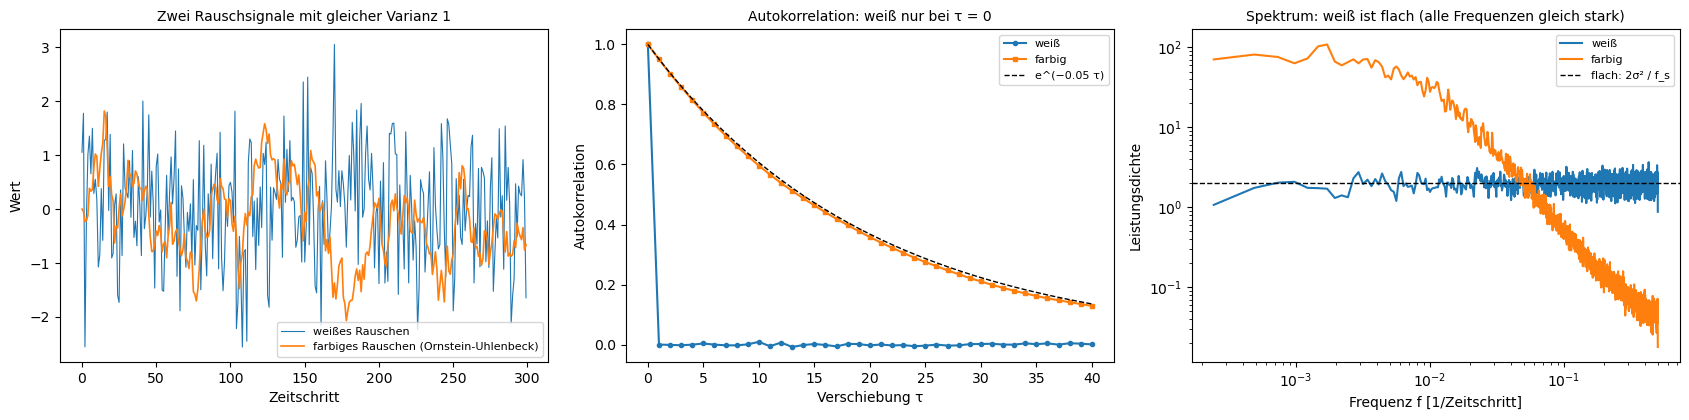

Weiß: Autokorrelation bei τ = 1 ... 5: [-0.     -0.0012 -0.0023 -0.0003  0.0035]  (Theorie 0, Schwankung ±1/√n = ±0.0039)
Weiß: Leistungsdichte im Mittel 2.000 (Theorie 2σ²/f_s = 2), unter f = 0.01: 1.933, über f = 0.25: 2.002
Farbig: Leistungsdichte bei f = 0.002 und f = 0.4: 65.2 und 0.0780


In [7]:
rng = np.random.default_rng(6)
n, fs = 2 ** 16, 1.0
white = rng.normal(0, 1, n)
colored = ornstein_uhlenbeck(0.0, 0.05, np.sqrt(2 * 0.05), n - 1, 1.0, rng)[0]   # zum Vergleich: korreliertes Rauschen, Varianz 1
f_w, psd_w = signal.welch(white, fs=fs, nperseg=4096)
f_c, psd_c = signal.welch(colored, fs=fs, nperseg=4096)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].plot(white[:300], lw=0.8, label="weißes Rauschen")
axes[0].plot(colored[:300], lw=1.2, label="farbiges Rauschen (Ornstein-Uhlenbeck)")
axes[0].set_xlabel("Zeitschritt")
axes[0].set_ylabel("Wert")
axes[0].set_title("Zwei Rauschsignale mit gleicher Varianz 1", fontsize=10)
axes[0].legend(fontsize=8, loc="lower right")
lags = np.arange(41)
axes[1].plot(lags, autocorrelation(white, 40), "o-", ms=3, label="weiß")
axes[1].plot(lags, autocorrelation(colored, 40), "s-", ms=3, label="farbig")
axes[1].plot(lags, np.exp(-0.05 * lags), "k--", lw=1, label="e^(−0.05 τ)")
axes[1].set_xlabel("Verschiebung τ")
axes[1].set_ylabel("Autokorrelation")
axes[1].set_title("Autokorrelation: weiß nur bei τ = 0", fontsize=10)
axes[1].legend(fontsize=8)
axes[2].loglog(f_w[1:], psd_w[1:], label="weiß")
axes[2].loglog(f_c[1:], psd_c[1:], label="farbig")
axes[2].axhline(2.0, color="k", ls="--", lw=1, label="flach: 2σ² / f_s")
axes[2].set_xlabel("Frequenz f [1/Zeitschritt]")
axes[2].set_ylabel("Leistungsdichte")
axes[2].set_title("Spektrum: weiß ist flach (alle Frequenzen gleich stark)", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

ac = autocorrelation(white, 5)
print(f"Weiß: Autokorrelation bei τ = 1 ... 5: {np.round(ac[1:], 4)}  (Theorie 0, Schwankung ±1/√n = ±{1 / np.sqrt(n):.4f})")
print(f"Weiß: Leistungsdichte im Mittel {psd_w.mean():.3f} (Theorie 2σ²/f_s = 2), unter f = 0.01: {psd_w[(f_w > 0) & (f_w < 0.01)].mean():.3f}, über f = 0.25: {psd_w[f_w > 0.25].mean():.3f}")
print(f"Farbig: Leistungsdichte bei f = 0.002 und f = 0.4: {np.interp(0.002, f_c, psd_c):.1f} und {np.interp(0.4, f_c, psd_c):.4f}")

* Im **linken Bild** springt das weiße Rauschen von Wert zu Wert ohne Zusammenhang; das farbige wandert langsam und bleibt eine Weile auf einer Seite, obwohl beide dieselbe Varianz haben. Im **mittleren Bild** fällt die Autokorrelation des weißen Rauschens nach $\tau = 0$ sofort auf null; laut **Ausgabe** liegen die Werte bei $\tau = 1$ bis 5 alle innerhalb $\pm0.0039$, der Schwankung, die man bei $2^{16}$ Werten erwartet. Die Autokorrelation des farbigen folgt $e^{-0.05\tau}$, ein Gedächtnis von etwa 20 Schritten.
* Im **rechten Bild** liegt das Spektrum des weißen Rauschens flach bei 2 (Ausgabe: Mittel 2.000; unter $f = 0.01$ im Mittel 1.933, über $f = 0.25$ 2.002). Das farbige hat bei tiefen Frequenzen viel mehr Leistung (65.2 bei $f = 0.002$) und bei hohen viel weniger (0.078 bei $f = 0.4$); die Kurven kreuzen sich bei $f\approx0.05$. Das ist die Antwort auf die Vorhersage: Gleiche Varianz heißt gleiche Fläche unter dem Spektrum, das farbige Rauschen verschiebt Leistung von hohen zu tiefen Frequenzen.
* **Wo es vorkommt:** **thermisches Rauschen** in elektrischen Widerständen (Johnson-Nyquist) ist bis zu sehr hohen Frequenzen weiß. In Statistik und ML ist weißes Rauschen das Standardmodell für Messfehler ($y = f(x) + \varepsilon$); die Reste eines guten Zeitreihenmodells sollen weiß sein (Ljung-Box-Test). Ingenieure messen mit weißem Rauschen den Frequenzgang von Systemen, **Diffusionsmodelle** fügen Bildern schrittweise Gaußsches Rauschen hinzu und lernen es wieder zu entfernen. Farbiges Rauschen mit Spektrum $1/f$ findet man in elektronischen Bauteilen, in supraleitenden Qubits, im Herzschlag und in der Musik.

##### *7. Die Brownsche Bewegung*

Wie rau sind die Pfade der Brownschen Bewegung, und was bleibt beim Verfeinern endlich? Vorher vorhersagen: Man misst die Länge eines Pfads auf $[0, 1]$ mit immer feinerem Raster. Nähert sie sich einem festen Wert?

Simuliert werden 2000 Pfade mit 1024 Schritten (für Varianz und Kovarianz) und ein einzelner fein aufgelöster Pfad mit $2^{16}$ Schritten. Links stehen sechs Pfade mit $\pm\sqrt t$. In der Mitte wird der feine Pfad mit $n = 2^4$ bis $2^{16}$ Teilintervallen abgetastet; für jedes $n$ werden die Summe der Quadrate der Zuwächse (quadratische Variation) und die Summe ihrer Beträge (die Länge) berechnet. Rechts wird der Ausschnitt $[0, 0.01]$ in der Zeit um 100 und in der Höhe um 10 gestreckt und neben den ganzen Pfad gelegt.

**Hintergrund & Fachbegriffe:**
- **Brownsche Bewegung** (Wiener-Prozess): stetige Pfade, unabhängige normalverteilte Zuwächse mit Varianz gleich der Zeitdifferenz.
- **Kovarianz** $\min(s, t)$: Zwei Zeitpunkte teilen den gemeinsamen Weg bis zum früheren.
- **Quadratische Variation:** $\sum(\Delta W)^2$ über eine Zerlegung von $[0, t]$; strebt gegen $t$.
- **Variation** (Länge): $\sum\vert\Delta W\vert$; bei differenzierbaren Kurven endlich, bei der Brownschen Bewegung unendlich.
- **Selbstähnlichkeit:** $W(ct)$ ist verteilt wie $\sqrt c\,W(t)$; man streckt also die Zeit um $1/c$ und die Höhe um $1/\sqrt c$.

**Theorie:**

- **Definition:** $W(0) = 0$; unabhängige Zuwächse; $W(t) - W(s)$ normalverteilt mit Mittelwert 0 und Varianz $t - s$; stetige Pfade (Wiener 1923).
- **Kovarianz:** Für $s < t$ ist $W(t) = W(s) + (W(t) - W(s))$, und der zweite Teil ist von $W(s)$ unabhängig. Also $\mathrm{Cov}(W(s), W(t)) = \mathrm{Var}(W(s)) = s = \min(s, t)$. Die Brownsche Bewegung ist ein Gauß-Prozess, ein Markov-Prozess und ein Martingal.
- **Selbstähnlich** mit $H = \tfrac12$: $W(ct)$ ist verteilt wie $\sqrt c\,W(t)$.
- **Nirgends differenzierbar, unendlich lang:** Über ein Intervall der Länge $\Delta t$ ändert sich $W$ um etwa $\sqrt{\Delta t}$, die Steigung $\sqrt{\Delta t}/\Delta t = 1/\sqrt{\Delta t}$ wächst ohne Grenze. Genauer ist $\mathbb E\vert\Delta W\vert = \sqrt{2\Delta t/\pi}$; bei $n$ Teilintervallen von $[0, 1]$ ist die Länge also etwa $n\sqrt{2/(\pi n)} = \sqrt{2n/\pi}\to\infty$.
- **Quadratische Variation:** Jedes $(\Delta W)^2$ hat Mittelwert $\Delta t$, die Summe also Mittelwert $t$; ihre Varianz ist $2n\,\Delta t^2 = 2t^2/n\to0$. Deshalb strebt $\sum(\Delta W)^2$ für jeden Pfad gegen $t$, kurz $(\mathrm dW)^2 = \mathrm dt$; das ist der Ursprung des Zusatzterms in Itôs Lemma (Abschnitt 4 der Theorie).
- **Diffusion:** Teilchen mit $X = \sqrt{2D}\,W$ und **Diffusionskonstante** $D$ haben die mittlere quadratische Verschiebung $\langle x^2\rangle = 2Dt$ (Einstein 1905), und ihre Dichte erfüllt die **Wärmeleitungsgleichung** $\partial_tp = D\,\partial_x^2p$.

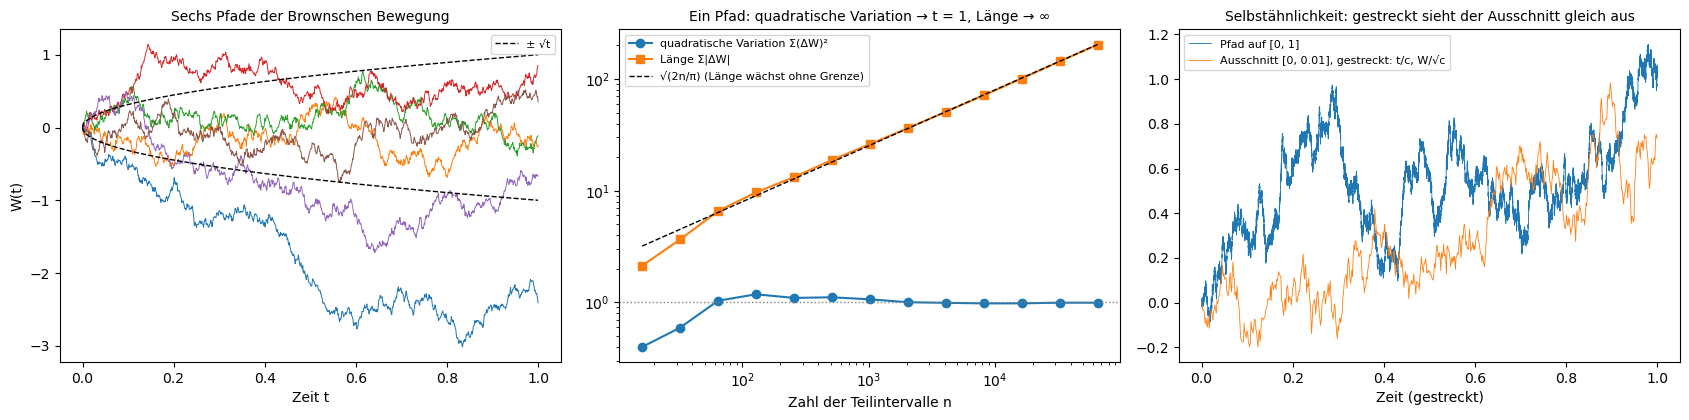

Varianz von W(t) bei t = 0.25, 0.5, 1: 0.254, 0.490, 1.000  (Theorie = t)
Kovarianz E[W(0.3) W(0.8)] = 0.298  (Theorie min(s, t) = 0.3)
Quadratische Variation bei n = 16, 256, 4096, 65536: 0.398, 1.097, 0.991, 0.993  (Theorie → 1)
Länge des Pfads bei n = 16, 256, 4096, 65536: 2.1, 13.2, 51.0, 203.5  (wächst wie √(2n/π))


In [8]:
rng = np.random.default_rng(7)
t, W = brownian(2000, 1024, T=1.0, rng=rng)                      # Ensemble für Varianz und Kovarianz
tz, Wz = brownian(1, 2 ** 16, T=1.0, rng=rng)                    # ein fein aufgelöster Pfad

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for r in range(6):
    axes[0].plot(t, W[r], lw=0.7)
axes[0].plot(t, np.sqrt(t), "k--", lw=1, label="± √t")
axes[0].plot(t, -np.sqrt(t), "k--", lw=1)
axes[0].set_xlabel("Zeit t")
axes[0].set_ylabel("W(t)")
axes[0].set_title("Sechs Pfade der Brownschen Bewegung", fontsize=10)
axes[0].legend(fontsize=8)
levels = np.arange(4, 17)
qv, tv = [], []
for L in levels:
    w = Wz[0, :: 2 ** (16 - L)]                                   # derselbe Pfad, mit 2^L Schritten abgetastet
    qv.append(np.sum(np.diff(w) ** 2)); tv.append(np.sum(np.abs(np.diff(w))))
axes[1].loglog(2 ** levels, qv, "o-", label="quadratische Variation Σ(ΔW)²")
axes[1].loglog(2 ** levels, tv, "s-", label="Länge Σ|ΔW|")
axes[1].loglog(2 ** levels, np.sqrt(2 * 2 ** levels / np.pi), "k--", lw=1, label="√(2n/π) (Länge wächst ohne Grenze)")
axes[1].axhline(1, color="grey", ls=":", lw=1)
axes[1].set_xlabel("Zahl der Teilintervalle n")
axes[1].set_title("Ein Pfad: quadratische Variation → t = 1, Länge → ∞", fontsize=10)
axes[1].legend(fontsize=8)
c = 0.01
mask = tz <= c
axes[2].plot(tz, Wz[0], lw=0.6, label="Pfad auf [0, 1]")
axes[2].plot(tz[mask] / c, Wz[0, mask] / np.sqrt(c), lw=0.6, label="Ausschnitt [0, 0.01], gestreckt: t/c, W/√c")
axes[2].set_xlabel("Zeit (gestreckt)")
axes[2].set_title("Selbstähnlichkeit: gestreckt sieht der Ausschnitt gleich aus", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Varianz von W(t) bei t = 0.25, 0.5, 1: " + ", ".join(f"{W[:, np.searchsorted(t, s)].var():.3f}" for s in (0.25, 0.5, 1.0)) + "  (Theorie = t)")
cov = np.mean(W[:, np.searchsorted(t, 0.3)] * W[:, np.searchsorted(t, 0.8)])
print(f"Kovarianz E[W(0.3) W(0.8)] = {cov:.3f}  (Theorie min(s, t) = 0.3)")
print(f"Quadratische Variation bei n = 16, 256, 4096, 65536: {qv[0]:.3f}, {qv[4]:.3f}, {qv[8]:.3f}, {qv[12]:.3f}  (Theorie → 1)")
print(f"Länge des Pfads bei n = 16, 256, 4096, 65536: {tv[0]:.1f}, {tv[4]:.1f}, {tv[8]:.1f}, {tv[12]:.1f}  (wächst wie √(2n/π))")

* Das **linke Bild** zeigt Pfade wie beim Random Walk (Exp. 2), nur in beliebig feiner Auflösung; ihre typische Größe ist $\pm\sqrt t$. Laut **Ausgabe** ist die Varianz bei $t = 0.25, 0.5, 1$ gleich 0.254, 0.490, 1.000 und die Kovarianz $\mathbb E[W(0.3)W(0.8)] = 0.298$ (Theorie $\min = 0.3$).
* Im **mittleren Bild** (doppelt logarithmisch) wächst die Länge entlang der Geraden $\sqrt{2n/\pi}$: 2.1, 13.2, 51.0, 203.5 bei $n = 16, 256, 4096, 65536$. Die Antwort auf die Vorhersage ist also nein: Die Länge ist unendlich, jede Verfeinerung findet neue Zacken. Die quadratische Variation pendelt sich dagegen bei 1 ein (0.398, 1.097, 0.991, 0.993); bei nur 16 Teilintervallen schwankt sie noch stark, weil sie dann aus nur 16 Quadraten besteht. Diese endliche Summe der Quadrate ist der Grund für $(\mathrm dW)^2 = \mathrm dt$ im Itô-Kalkül.
* Im **rechten Bild** sieht der hundertfach vergrößerte Ausschnitt (orange) statistisch genauso aus wie der ganze Pfad (blau). Es gibt keinen Maßstab, auf dem der Pfad glatt wird; eine differenzierbare Kurve würde beim Vergrößern dagegen zur Geraden. **Wo sie vorkommt:** Diffusion von Teilchen (Einstein; Perrin bestimmte damit 1908 die Avogadro-Zahl), Wärmeleitung, das Bachelier-Modell für Kurse, Rauschen in Regelung und Filterung (Kalman-Bucy-Filter), **Langevin-Dynamik** in MCMC-Verfahren und als Modell für das Rauschen des stochastischen Gradientenabstiegs, die SDE-Formulierung von **Diffusionsmodellen** und Pfadintegrale in der Physik (Feynman-Kac-Formel). Sie ist der Baustein aller Prozesse in Exp. 8 bis 11.

##### *8. Die Brownsche Brücke*

Wie verhält sich eine Brownsche Bewegung, deren Endpunkt festliegt, und was hat sie mit einem Statistik-Test zu tun? Vorher vorhersagen: Wo ist die Unsicherheit einer Brücke am größten, und wie groß ist ihre Varianz dort?

Aus 4000 Pfaden der Brownschen Bewegung werden Brücken $B(t) = W(t) - t\,W(1)$ gebaut. Links stehen sechs Brücken mit $\pm\sqrt{t(1 - t)}$, in der Mitte die gemessene Varianz gegen $t(1 - t)$. Rechts der Zusammenhang mit dem Kolmogorov-Smirnov-Test: 5000-mal werden 200 gleichverteilte Zufallszahlen gezogen und gegen die (richtige) Gleichverteilung getestet; das Histogramm der Teststatistik $\sqrt n\sup\vert F_n - F\vert$ wird mit der Kolmogorov-Verteilung verglichen, der Verteilung des Maximums von $\vert B\vert$.

**Hintergrund & Fachbegriffe:**
- **Brownsche Brücke:** eine Brownsche Bewegung auf $[0, 1]$, die bei 0 enden muss; Varianz $t(1 - t)$.
- **Empirische Verteilungsfunktion** $F_n(x)$: der Anteil der Stichprobe, der kleiner oder gleich $x$ ist; eine Treppe.
- **Kolmogorov-Smirnov-Test:** prüft, ob eine Stichprobe einer vermuteten Verteilung $F$ folgt, über den größten Abstand $\sup\vert F_n - F\vert$.
- **Kolmogorov-Verteilung:** die Verteilung von $\sup_t\vert B(t)\vert$; Mittelwert 0.869, 95-%-Quantil 1.358.
- **Signifikanzniveau:** die Wahrscheinlichkeit, mit der ein Test eine richtige Annahme fälschlich ablehnt; hier 5 %.

**Theorie:**

- **Varianz und Kovarianz:** Aus $B(t) = W(t) - t\,W(1)$ folgt $\mathrm{Var}(B(t)) = t - 2t\cdot t + t^2 = t(1 - t)$ und $\mathrm{Cov}(B(s), B(t)) = \min(s, t) - st$.
- **Bedingte Brownsche Bewegung:** $B$ ist unabhängig von $W(1)$; deshalb hat $B$ dieselbe Verteilung wie eine Brownsche Bewegung unter der Bedingung $W(1) = 0$. Die Brücke ist ein Gauß- und ein Markov-Prozess, aber kein Martingal: Sie wird zum Ende hin zu 0 gezogen, als SDE $\mathrm dB = -\frac B{1 - t}\,\mathrm dt + \mathrm dW$.
- **Verbindung zum KS-Test:** Für gleichverteilte Daten ist $F(u) = u$, und $n\,F_n(u)$ ist binomialverteilt mit Varianz $nu(1 - u)$. Also hat $\sqrt n\,(F_n(u) - u)$ die Varianz $u(1 - u)$ und die Kovarianz $\min(u, v) - uv$, genau die der Brücke; für großes $n$ wird $\sqrt n\,(F_n - F)$ zur Brownschen Brücke. Jede stetige Verteilung lässt sich durch $u = F(x)$ auf die Gleichverteilung zurückführen, deshalb hängt der Test nicht von $F$ ab.
- **Kolmogorov-Verteilung:** $P(\sup_t\vert B(t)\vert\leq x) = 1 - 2\sum_{k\geq1}(-1)^{k - 1}e^{-2k^2x^2}$. Größere Werte der Statistik als das 95-%-Quantil 1.358 lehnt der Test ab.

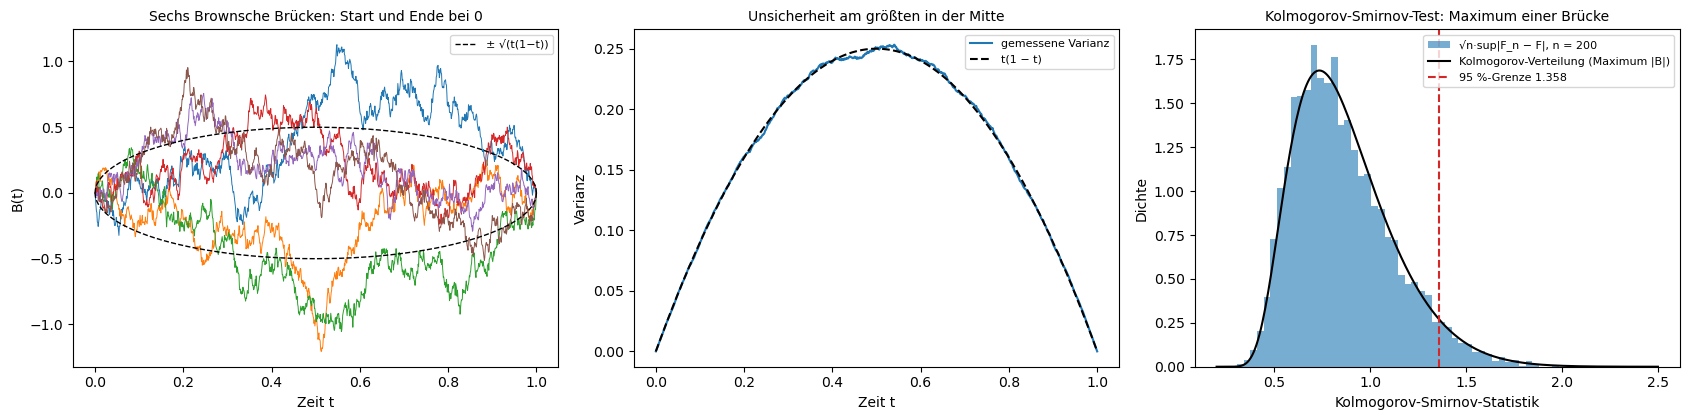

Varianz bei t = 0.5: 0.2505 (Theorie 0.25); bei t = 0.1: 0.0897 (Theorie 0.09)
Maximum |B| der Brücken im Mittel 0.852 (Kolmogorov-Verteilung: 0.869; auf dem Gitter etwas kleiner)
KS-Statistik: Mittel 0.857, Anteil über 1.358: 0.049 (soll 0.05)


In [9]:
rng = np.random.default_rng(8)
t, W = brownian(4000, 1000, T=1.0, rng=rng)
B = W - t * W[:, -1:]                                            # Brownsche Brücke: B(t) = W(t) − t·W(1)

n_samples, reps = 200, 5000
U = np.sort(rng.random((reps, n_samples)), axis=1)               # gleichverteilte Stichproben, sortiert
i = np.arange(1, n_samples + 1)
D = np.maximum(i / n_samples - U, U - (i - 1) / n_samples).max(axis=1)   # Kolmogorov-Smirnov-Abstand sup|F_n − F|
KS = np.sqrt(n_samples) * D

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for r in range(6):
    axes[0].plot(t, B[r], lw=0.7)
axes[0].plot(t, np.sqrt(t * (1 - t)), "k--", lw=1, label="± √(t(1−t))")
axes[0].plot(t, -np.sqrt(t * (1 - t)), "k--", lw=1)
axes[0].set_xlabel("Zeit t")
axes[0].set_ylabel("B(t)")
axes[0].set_title("Sechs Brownsche Brücken: Start und Ende bei 0", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].plot(t, B.var(axis=0), label="gemessene Varianz")
axes[1].plot(t, t * (1 - t), "k--", label="t(1 − t)")
axes[1].set_xlabel("Zeit t")
axes[1].set_ylabel("Varianz")
axes[1].set_title("Unsicherheit am größten in der Mitte", fontsize=10)
axes[1].legend(fontsize=8)
x = np.linspace(0.2, 2.5, 300)
axes[2].hist(KS, bins=50, density=True, alpha=0.6, label=f"√n·sup|F_n − F|, n = {n_samples}")
axes[2].plot(x, stats.kstwobign.pdf(x), "k-", label="Kolmogorov-Verteilung (Maximum |B|)")
axes[2].axvline(stats.kstwobign.ppf(0.95), color="tab:red", ls="--", label=f"95 %-Grenze {stats.kstwobign.ppf(0.95):.3f}")
axes[2].set_xlabel("Kolmogorov-Smirnov-Statistik")
axes[2].set_ylabel("Dichte")
axes[2].set_title("Kolmogorov-Smirnov-Test: Maximum einer Brücke", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Varianz bei t = 0.5: {B[:, 500].var():.4f} (Theorie 0.25); bei t = 0.1: {B[:, 100].var():.4f} (Theorie 0.09)")
print(f"Maximum |B| der Brücken im Mittel {np.abs(B).max(axis=1).mean():.3f} (Kolmogorov-Verteilung: {stats.kstwobign.mean():.3f}; "
      f"auf dem Gitter etwas kleiner)")
print(f"KS-Statistik: Mittel {KS.mean():.3f}, Anteil über 1.358: {np.mean(KS > stats.kstwobign.ppf(0.95)):.3f} (soll 0.05)")

* Im **linken Bild** starten und enden alle Brücken bei 0, dazwischen wandern sie frei innerhalb eines Rahmens $\pm\sqrt{t(1 - t)}$, der in der Mitte am weitesten ist. Das **mittlere Bild** zeigt die Varianz als Parabel $t(1 - t)$. Die Antwort auf die Vorhersage: in der Mitte, mit Varianz $1/4$; laut **Ausgabe** 0.2505 bei $t = 0.5$ und 0.0897 bei $t = 0.1$ (Theorie 0.09).
* Im **rechten Bild** liegt das Histogramm der KS-Statistik auf der Kolmogorov-Dichte. Mittelwert 0.857, Anteil über 1.358 genau 0.049, wie vorgesehen 5 %: Ein Test mit richtiger Annahme lehnt in 5 % der Fälle zufällig ab. Das Maximum $\vert B\vert$ der simulierten Brücken ist im Mittel 0.852 statt 0.869, weil man auf einem Gitter von 1000 Punkten die Spitzen zwischen den Gitterpunkten verpasst. Dass das Maximum einer Brücke herauskommt, hat einen einfachen Grund: $F_n - F$ ist an beiden Enden 0 (bei $-\infty$ und $+\infty$) und dazwischen eine Summe vieler kleiner Zufallsabweichungen.
* **Wo sie vorkommt:** im **KS-Test** und verwandten Anpassungstests (Cramér-von-Mises, Anderson-Darling), etwa um im Betrieb eines ML-Modells zu prüfen, ob sich die Verteilung der Eingabedaten gegenüber dem Training verschoben hat (**Data Drift**). Mit Brücken verfeinert man simulierte Pfade zwischen bekannten Punkten (Brownian-Bridge-Konstruktion in Monte-Carlo-Verfahren der Optionsbewertung), modelliert Tierbewegungen zwischen zwei GPS-Ortungen (Brownian Bridge Movement Model) und beschreibt den Preis einer Anleihe, deren Wert bei Fälligkeit feststeht.

##### *9. Die geometrische Brownsche Bewegung*

Warum ist der typische Verlauf eines Kurses schlechter als sein Mittelwert? Vorher vorhersagen: Eine Aktie hat eine erwartete Rendite von 7 % pro Jahr und eine Volatilität von 30 %. Welcher Anteil der Pfade liegt nach 30 Jahren unter dem Startwert?

Simuliert werden 10 000 Pfade der geometrischen Brownschen Bewegung mit $S_0 = 100$, $\mu = 0.07$, $\sigma = 0.3$ in Monatsschritten über 30 Jahre, mit der exakten Lösung aus dem Theorie-Block unten. Links stehen 30 Pfade (logarithmische y-Achse) mit Mittelwert und Median, in der Mitte die Verteilung des Endkurses auf logarithmischer Achse mit der Log-Normalverteilung, rechts der Anteil der Pfade unter dem Mittelwert im Lauf der Zeit mit der Vorhersage $\Phi(\sigma\sqrt t/2)$.

**Hintergrund & Fachbegriffe:**
- **Geometrische Brownsche Bewegung:** Die relativen Änderungen $\mathrm dS/S$ sind Brownsch, mit **Drift** $\mu$ (erwartete Rendite pro Jahr) und **Volatilität** $\sigma$ (Standardabweichung der Rendite pro Jahr).
- **Log-Normalverteilung:** $\ln S$ ist normalverteilt; $S$ bleibt positiv und hat einen langen rechten Rand.
- **Median:** der Wert, den die Hälfte der Pfade übertrifft; der typische Ausgang.
- **Volatilitätsabzug:** Der Median wächst mit $\mu - \sigma^2/2$, nicht mit $\mu$; der Term $\sigma^2/2$ kommt aus Itôs Lemma.
- $\Phi$: die Verteilungsfunktion der Standardnormalverteilung.

**Theorie:**

- **Lösung:** Itôs Lemma (Abschnitt 4 der Theorie) für $f(S) = \ln S$ mit $f' = 1/S$, $f'' = -1/S^2$ und $b = \sigma S$ gibt $\mathrm d\ln S = (\mu - \tfrac12\sigma^2)\,\mathrm dt + \sigma\,\mathrm dW$. Also ist
$$S(t) = S_0\exp\big((\mu - \tfrac12\sigma^2)t + \sigma W(t)\big),$$
und $\ln S(t)$ ist normalverteilt mit Mittelwert $\ln S_0 + (\mu - \tfrac12\sigma^2)t$ und Varianz $\sigma^2t$.
- **Mittelwert und Median:** Der Median von $S$ ist $e^{\text{Median von }\ln S} = S_0e^{(\mu - \sigma^2/2)t}$. Für den Mittelwert braucht man $\mathbb E[e^{\sigma W(t)}] = e^{\sigma^2t/2}$; das hebt den Abzug genau auf: $\mathbb E[S(t)] = S_0e^{\mu t}$.
- **Anteil unter dem Mittelwert:** $S(t) < S_0e^{\mu t}$ heißt $\sigma W(t) < \tfrac12\sigma^2t$, also $W(t)/\sqrt t < \tfrac12\sigma\sqrt t$; die Wahrscheinlichkeit ist $\Phi(\sigma\sqrt t/2)$ und strebt gegen 1. Ebenso ist der Anteil unter dem Startwert $\Phi\big(-(\mu - \tfrac12\sigma^2)\sqrt t/\sigma\big)$.
- **Einordnung:** Die logarithmischen Zuwächse sind unabhängig und stationär; für $\mu = 0$ ist $S$ ein Martingal. GBM ist das Kursmodell der **Black-Scholes-Formel**; dort rechnet man mit dem risikoneutralen Maß, unter dem der abgezinste Kurs ein Martingal ist.

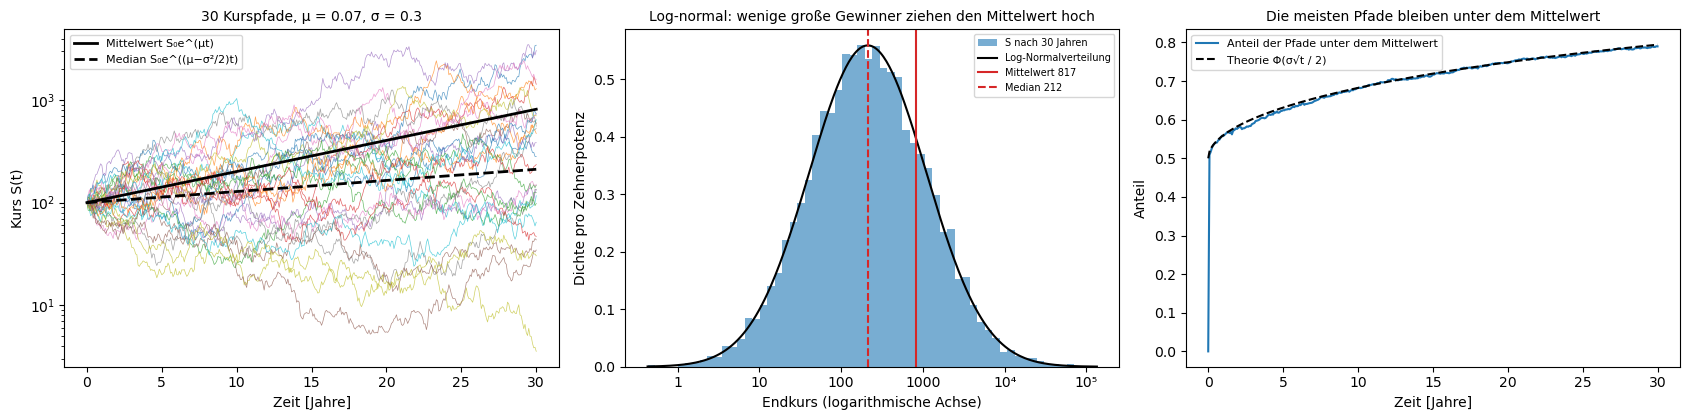

Nach 30 Jahren: Mittel 842 (Theorie 817), Median 211 (Theorie 212)
Anteil der Pfade unter dem Mittelwert: 0.790 (Theorie 0.794); unter dem Startwert 100: 0.325 (Theorie 0.324)
Typische Wachstumsrate (Median): μ − σ²/2 = 0.025 pro Jahr statt μ = 0.07


In [10]:
rng = np.random.default_rng(9)
S0, mu, sigma, years = 100.0, 0.07, 0.30, 30
t, W = brownian(10_000, years * 12, T=years, rng=rng)            # monatliche Schritte
S = S0 * np.exp((mu - 0.5 * sigma ** 2) * t + sigma * W)         # Lösung von dS = μ S dt + σ S dW (Itô)
mean_t, median_t = S0 * np.exp(mu * t), S0 * np.exp((mu - 0.5 * sigma ** 2) * t)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for r in range(30):
    axes[0].plot(t, S[r], lw=0.5, alpha=0.7)
axes[0].plot(t, mean_t, "k-", lw=2, label="Mittelwert S₀e^(μt)")
axes[0].plot(t, median_t, "k--", lw=2, label="Median S₀e^((μ−σ²/2)t)")
axes[0].set_yscale("log")
axes[0].set_xlabel("Zeit [Jahre]")
axes[0].set_ylabel("Kurs S(t)")
axes[0].set_title(f"30 Kurspfade, μ = {mu}, σ = {sigma}", fontsize=10)
axes[0].legend(fontsize=8)
end = S[:, -1]
logS = np.log10(end)                                             # log10 des Endkurses ist normalverteilt
axes[1].hist(logS, bins=60, density=True, alpha=0.6, label=f"S nach {years} Jahren")
xs = np.linspace(logS.min(), logS.max(), 300)
axes[1].plot(xs, stats.norm.pdf(xs, np.log10(median_t[-1]), sigma * np.sqrt(years) / np.log(10)), "k-", label="Log-Normalverteilung")
axes[1].axvline(np.log10(mean_t[-1]), color="tab:red", ls="-", label=f"Mittelwert {mean_t[-1]:.0f}")
axes[1].axvline(np.log10(median_t[-1]), color="tab:red", ls="--", label=f"Median {median_t[-1]:.0f}")
axes[1].set_xticks(range(0, 6), ["1", "10", "100", "1000", "10⁴", "10⁵"])
axes[1].set_xlabel("Endkurs (logarithmische Achse)")
axes[1].set_ylabel("Dichte pro Zehnerpotenz")
axes[1].set_title("Log-normal: wenige große Gewinner ziehen den Mittelwert hoch", fontsize=10)
axes[1].legend(fontsize=7)
below = (S < mean_t).mean(axis=0)
axes[2].plot(t, below, label="Anteil der Pfade unter dem Mittelwert")
axes[2].plot(t, stats.norm.cdf(0.5 * sigma * np.sqrt(t)), "k--", label="Theorie Φ(σ√t / 2)")
axes[2].set_xlabel("Zeit [Jahre]")
axes[2].set_ylabel("Anteil")
axes[2].set_title("Die meisten Pfade bleiben unter dem Mittelwert", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Nach {years} Jahren: Mittel {end.mean():.0f} (Theorie {mean_t[-1]:.0f}), Median {np.median(end):.0f} (Theorie {median_t[-1]:.0f})")
print(f"Anteil der Pfade unter dem Mittelwert: {np.mean(end < mean_t[-1]):.3f} (Theorie {stats.norm.cdf(0.5 * sigma * np.sqrt(years)):.3f}); "
      f"unter dem Startwert {S0:.0f}: {np.mean(end < S0):.3f} (Theorie {stats.norm.cdf(-(mu - 0.5 * sigma ** 2) * np.sqrt(years) / sigma):.3f})")
print(f"Typische Wachstumsrate (Median): μ − σ²/2 = {mu - 0.5 * sigma ** 2:.3f} pro Jahr statt μ = {mu}")

* Im **linken Bild** fächern die Pfade auf. Der Mittelwert (durchgezogen) wächst mit 7 %, der Median (gestrichelt) nur mit 2.5 % pro Jahr; nach 30 Jahren liegen deutlich mehr Pfade unter der Mittelwertkurve als darüber. Das **mittlere Bild** zeigt den Endkurs auf logarithmischer Achse: eine Glockenkurve mit Gipfel beim Median, 211 (Theorie 212). Der Mittelwert 842 (Theorie 817) liegt weit rechts davon; ihn tragen die wenigen Pfade mit Endkursen über $10^4$. Weil er an diesen seltenen Werten hängt, schwankt der gemessene Mittelwert stark (hier 3 % zu hoch), der Median kaum.
* Im **rechten Bild** steigt der Anteil der Pfade unter dem Mittelwert von 0.5 auf 0.790 nach 30 Jahren (Theorie 0.794). Laut **Ausgabe** liegen 32.5 % der Pfade unter dem Startwert 100 (Theorie 32.4 %); das ist die Antwort auf die Vorhersage: rund ein Drittel, trotz 7 % erwarteter Rendite. Die typische Wachstumsrate ist $\mu - \sigma^2/2 = 2.5\,\%$: Schwankungen kosten Wachstum, denn ein Verlust von 50 % braucht danach einen Gewinn von 100 %, um ausgeglichen zu werden.
* **Wo sie vorkommt:** im **Black-Scholes-Modell** für Optionspreise und in Risikomodellen der Banken (Value at Risk), im **Kelly-Kriterium** und in der Portfolio-Theorie, die die Wachstumsrate $\mu - \sigma^2/2$ statt der mittleren Rendite maximieren, bei Populationen mit zufällig schwankender Wachstumsrate (Umweltrauschen) und in der **Ergodizitätsökonomie**: Der Mittelwert über alle Pfade ist nicht das, was ein einzelner Anleger im Lauf der Zeit erlebt.

##### *10. Der Ornstein-Uhlenbeck-Prozess*

Wie schnell kehrt ein Prozess mit Rückstellkraft zum Mittelwert zurück, und wie lange erinnert er sich an seine Vergangenheit? Vorher vorhersagen: Der Prozess startet bei 3, mit $\theta = 1$ und $\sigma = 1$. Wo liegt er im Mittel bei $t = 1$, und wie groß ist seine Streuung im Gleichgewicht?

Simuliert wird der Ornstein-Uhlenbeck-Prozess mit $\theta = \sigma = 1$ und Zeitschritt $0.01$, exakt diskretisiert. Links stehen je drei Pfade ab $-3$, $0$ und $3$ mit den Mittelwertkurven $\pm3e^{-\theta t}$ und dem Band von $\pm2$ stationären Standardabweichungen. Ein langer Pfad über $2^{19}$ Schritte (etwa 5200 Zeiteinheiten) liefert die Autokorrelation (Mitte) und das Leistungsspektrum (rechts) im Vergleich mit $e^{-\theta\tau}$ und der Lorentz-Kurve. Die Ausgabe prüft außerdem Mittelwert und Varianz von 4000 Pfaden ab $x_0 = 3$ bei $t = 1$.

**Hintergrund & Fachbegriffe:**
- **Mean Reversion:** Eine Kraft $-\theta X$ zieht den Prozess zum Mittelwert 0 zurück; je weiter weg, desto stärker.
- **Korrelationszeit** $1/\theta$: die Zeit, nach der die Autokorrelation auf $1/e\approx0.37$ gefallen ist.
- **Stationäre Verteilung:** Normalverteilung mit Varianz $\sigma^2/(2\theta)$; das Gleichgewicht zwischen Rückstellkraft und Rauschen.
- **Lorentz-Spektrum:** $2\sigma^2/(\theta^2 + \omega^2)$ mit $\omega = 2\pi f$; flach unterhalb der **Eckfrequenz** $\theta/2\pi\approx0.16$, darüber $\propto1/f^2$.
- **Exakte Diskretisierung:** Für den OU-Prozess ist der Schritt von $t$ nach $t + \Delta t$ exakt bekannt; das einfache Euler-Verfahren (Variation 5) wäre bei großen Schritten falsch.

**Theorie:**

- **Gleichung und Lösung:** $\mathrm dX = -\theta X\,\mathrm dt + \sigma\,\mathrm dW$. Ab $x_0$ ist $X(t)$ normalverteilt mit Mittelwert $x_0e^{-\theta t}$ und Varianz $\frac{\sigma^2}{2\theta}(1 - e^{-2\theta t})$; für große $t$ wird daraus die stationäre Verteilung mit Varianz $\sigma^2/(2\theta)$.
- **Autokorrelation und Spektrum:** Im stationären Zustand ist die Autokovarianz $\frac{\sigma^2}{2\theta}e^{-\theta\vert\tau\vert}$; ihre Fourier-Transformierte ist das einseitige Spektrum $2\sigma^2/(\theta^2 + \omega^2)$ mit $\omega = 2\pi f$.
- **Satz von Doob:** Bis auf Skalierung ist der OU-Prozess der einzige Prozess, der zugleich stationär, Gaußsch und Markovsch ist. Ursprünglich beschrieb er die Geschwindigkeit eines Brownschen Teilchens mit Reibung (Ornstein und Uhlenbeck 1930).
- **Exakte Simulation:** $X_{k+1} = e^{-\theta\Delta t}X_k + \sigma\sqrt{(1 - e^{-2\theta\Delta t})/(2\theta)}\,Z_k$ mit unabhängigen Standardnormalzahlen $Z_k$; das gilt für jeden Zeitschritt. Das **Euler-Maruyama-Verfahren** $X_{k+1} = (1 - \theta\Delta t)X_k + \sigma\sqrt{\Delta t}\,Z_k$ stimmt damit nur für $\theta\Delta t\ll1$ überein.

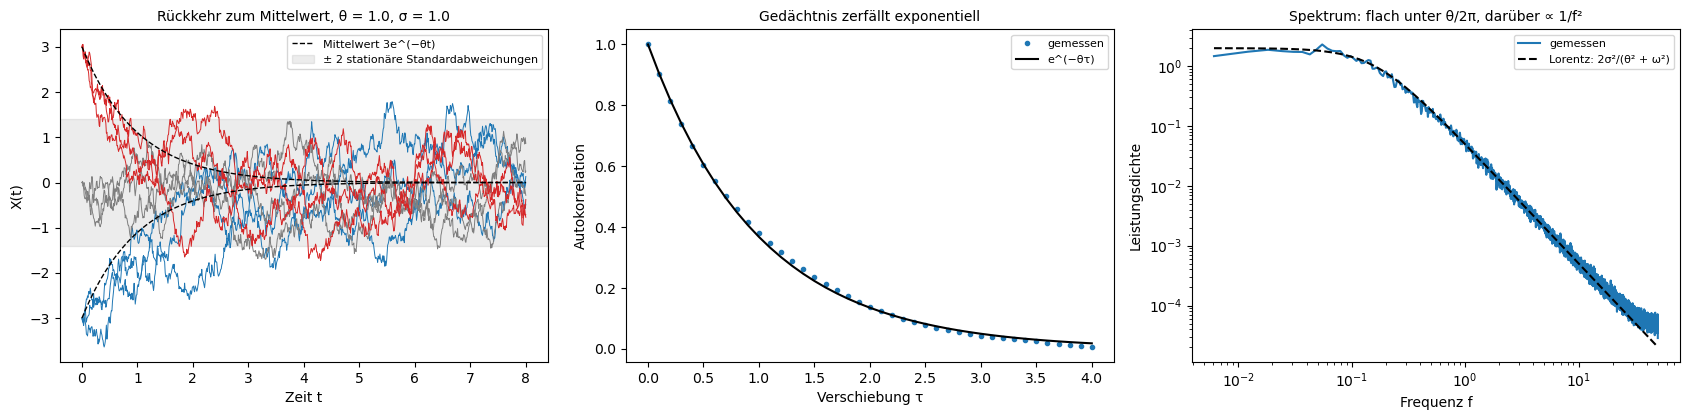

Stationäre Varianz: gemessen 0.4849, Theorie σ²/(2θ) = 0.5000
Autokorrelation bei τ = 1: 0.381 (Theorie e^−1 = 0.368); Korrelationszeit 1/θ = 1.0
4000 Pfade ab x₀ = 3, bei t = 1: Mittel 1.103 (Theorie 3e^−θt = 1.104), Varianz 0.434 (Theorie σ²(1 − e^−2θt)/(2θ) = 0.432)


In [11]:
rng = np.random.default_rng(10)
theta, sigma, dt = 1.0, 1.0, 0.01
starts = np.repeat([-3.0, 0.0, 3.0], 3)
X = ornstein_uhlenbeck(starts, theta, sigma, 800, dt, rng)
long = ornstein_uhlenbeck(0.0, theta, sigma, 2 ** 19, dt, rng)[0]
lag_steps = np.arange(0, 401, 10)
ac = autocorrelation(long, 400)[lag_steps]
f, psd = signal.welch(long, fs=1 / dt, nperseg=2 ** 14)
omega = 2 * np.pi * f

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
tt = np.arange(801) * dt
for r, x0 in enumerate(starts):
    axes[0].plot(tt, X[r], lw=0.7, c={-3.0: "tab:blue", 0.0: "tab:grey", 3.0: "tab:red"}[x0])
axes[0].plot(tt, 3 * np.exp(-theta * tt), "k--", lw=1, label="Mittelwert 3e^(−θt)")
axes[0].plot(tt, -3 * np.exp(-theta * tt), "k--", lw=1)
sd = sigma / np.sqrt(2 * theta)
axes[0].axhspan(-2 * sd, 2 * sd, color="grey", alpha=0.15, label="± 2 stationäre Standardabweichungen")
axes[0].set_xlabel("Zeit t")
axes[0].set_ylabel("X(t)")
axes[0].set_title(f"Rückkehr zum Mittelwert, θ = {theta}, σ = {sigma}", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].plot(lag_steps * dt, ac, "o", ms=3, label="gemessen")
axes[1].plot(lag_steps * dt, np.exp(-theta * lag_steps * dt), "k-", label="e^(−θτ)")
axes[1].set_xlabel("Verschiebung τ")
axes[1].set_ylabel("Autokorrelation")
axes[1].set_title("Gedächtnis zerfällt exponentiell", fontsize=10)
axes[1].legend(fontsize=8)
axes[2].loglog(f[1:], psd[1:], label="gemessen")
axes[2].loglog(f[1:], 2 * sigma ** 2 / (theta ** 2 + omega[1:] ** 2), "k--", label="Lorentz: 2σ²/(θ² + ω²)")
axes[2].set_xlabel("Frequenz f")
axes[2].set_ylabel("Leistungsdichte")
axes[2].set_title("Spektrum: flach unter θ/2π, darüber ∝ 1/f²", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Stationäre Varianz: gemessen {long.var():.4f}, Theorie σ²/(2θ) = {sigma ** 2 / (2 * theta):.4f}")
print(f"Autokorrelation bei τ = 1: {autocorrelation(long, 100)[100]:.3f} (Theorie e^−1 = {np.exp(-1):.3f}); Korrelationszeit 1/θ = {1 / theta}")
check = ornstein_uhlenbeck(np.full(4000, 3.0), theta, sigma, 100, dt, rng)[:, -1]   # 4000 Pfade ab x₀ = 3 bis t = 1
print(f"4000 Pfade ab x₀ = 3, bei t = 1: Mittel {check.mean():.3f} (Theorie 3e^−θt = {3 * np.exp(-1):.3f}), Varianz {check.var():.3f} (Theorie σ²(1 − e^−2θt)/(2θ) = {(1 - np.exp(-2)) / 2:.3f})")

* Im **linken Bild** werden die Pfade von $\pm3$ zur 0 gezogen und folgen im Mittel $\pm3e^{-t}$; nach etwa drei Korrelationszeiten ist der Anfang vergessen, und alle Pfade bleiben meist im grauen Band $\pm2\cdot0.71$. Die Antwort auf die Vorhersage steht in der **Ausgabe**: Bei $t = 1$ liegen 4000 Pfade im Mittel bei 1.103 (Theorie $3/e = 1.104$) mit Varianz 0.434 (Theorie 0.432); im Gleichgewicht ist die Varianz 0.4849 (Theorie 0.5), die Standardabweichung also etwa 0.7. Die Abweichung von 3 % liegt im Rahmen der Schwankung von etwa 2 %, die man bei einem Pfad über 5200 Korrelationszeiten erwartet.
* Das **mittlere Bild** zeigt die Autokorrelation entlang $e^{-\tau}$; bei $\tau = 1$ gemessen 0.381 (Theorie 0.368). Im **rechten Bild** ist das Spektrum flach unterhalb von etwa 0.16 und fällt darüber wie $1/f^2$. Auf langen Zeitskalen verhält sich der Prozess also wie weißes Rauschen, auf kurzen wie die Brownsche Bewegung. Ganz rechts, nahe der Nyquist-Frequenz 50, liegt die Messung etwas über der Kurve; das ist ein Effekt der Abtastung (Aliasing).
* **Wo er vorkommt:** **Zinsmodelle** (Vasicek-Modell), Rohstoffpreise und Preisdifferenzen in **Pairs Trading**, die Volatilität in stochastischen Volatilitätsmodellen, die Geschwindigkeit eines Brownschen Teilchens mit Reibung (**Langevin-Gleichung**), das Membranpotenzial von Neuronen, Temperaturanomalien in Klimamodellen (Hasselmann 1976) und allgemein jede Größe, die ein Regelkreis zu einem Sollwert zurückführt. Im Reinforcement Learning erzeugt OU-Rauschen zeitlich korrelierte Erkundung (DDPG); als Gauß-Prozess ist er der exponentielle Kern (Exp. 13).

##### *11. Die gebrochene Brownsche Bewegung*

Was ändert sich, wenn die Zuwächse einer Brownschen Bewegung korreliert sind? Vorher vorhersagen: Eine Zeitreihe ist eben gestiegen. Steigt sie im nächsten Schritt bei $H = 0.75$ eher weiter oder kehrt sie um? Und bei $H = 0.25$?

Für $H = 0.25$, $0.5$ und $0.75$ werden je 200 Pfade mit 1024 Schritten über die Cholesky-Zerlegung erzeugt. Links steht je ein Pfad, in der Mitte das Variogramm (mittleres Quadrat des Zuwachses gegen den Zeitabstand, doppelt logarithmisch) mit der gemessenen Steigung, rechts die Korrelation benachbarter Zuwächse gegen die Theorie $2^{2H - 1} - 1$.

**Hintergrund & Fachbegriffe:**
- **Hurst-Exponent** $H$: steuert die Korrelation der Zuwächse; $H = \tfrac12$ ist die Brownsche Bewegung.
- **Variogramm:** das mittlere Quadrat eines Zuwachses als Funktion des Zeitabstands, hier $\propto\Delta t^{2H}$.
- **Persistent / antipersistent:** positiv korrelierte Zuwächse (Trends setzen sich fort) bzw. negativ korrelierte (Umkehr wahrscheinlicher).
- **Langes Gedächtnis:** Korrelationen fallen nur wie eine Potenz ab; ihre Summe über alle Abstände ist unendlich.
- **Gebrochenes Gaußsches Rauschen** (fractional Gaussian noise): die Zuwächse der fBM, ein stationärer Gauß-Prozess.
- **Cholesky-Zerlegung:** $C = LL^T$ mit einer unteren Dreiecksmatrix $L$; $L$ mal ein Vektor unabhängiger Normalzahlen hat die Kovarianz $C$.

**Theorie:**

- **Kovarianz** (Mandelbrot und Van Ness 1968):
$$\mathrm{Cov}(B_H(s), B_H(t)) = \tfrac12\big(s^{2H} + t^{2H} - \vert t - s\vert^{2H}\big) .$$
Für $H = \tfrac12$ ist das $\min(s, t)$, die Brownsche Bewegung. Daraus folgen Selbstähnlichkeit mit Exponent $H$ und das Variogramm $\mathbb E[(B_H(t + \Delta t) - B_H(t))^2] = \Delta t^{2H}$.
- **Korrelation benachbarter Zuwächse:** Für die Zuwächse $B_H(1) - B_H(0)$ und $B_H(2) - B_H(1)$ gibt die Formel die Kovarianz $\tfrac12(2^{2H} - 2) = 2^{2H - 1} - 1$, bei Varianz 1 also $\rho(1) = 2^{2H - 1} - 1$.
- **Langes Gedächtnis:** Für Zuwächse im Abstand $k$ fällt die Korrelation wie $H(2H - 1)\,k^{2H - 2}$. Für $H > \tfrac12$ ist die Summe über alle $k$ unendlich. Für $H\neq\tfrac12$ ist die fBM weder Markovsch noch ein Martingal; in Finanzmodellen erlaubt sie deshalb Arbitrage.
- **Simulation:** Die Cholesky-Methode ist exakt, kostet aber $O(n^3)$ Rechenschritte; für lange Reihen nimmt man FFT-Verfahren (Davies-Harte), die die Stationarität der Zuwächse ausnutzen.

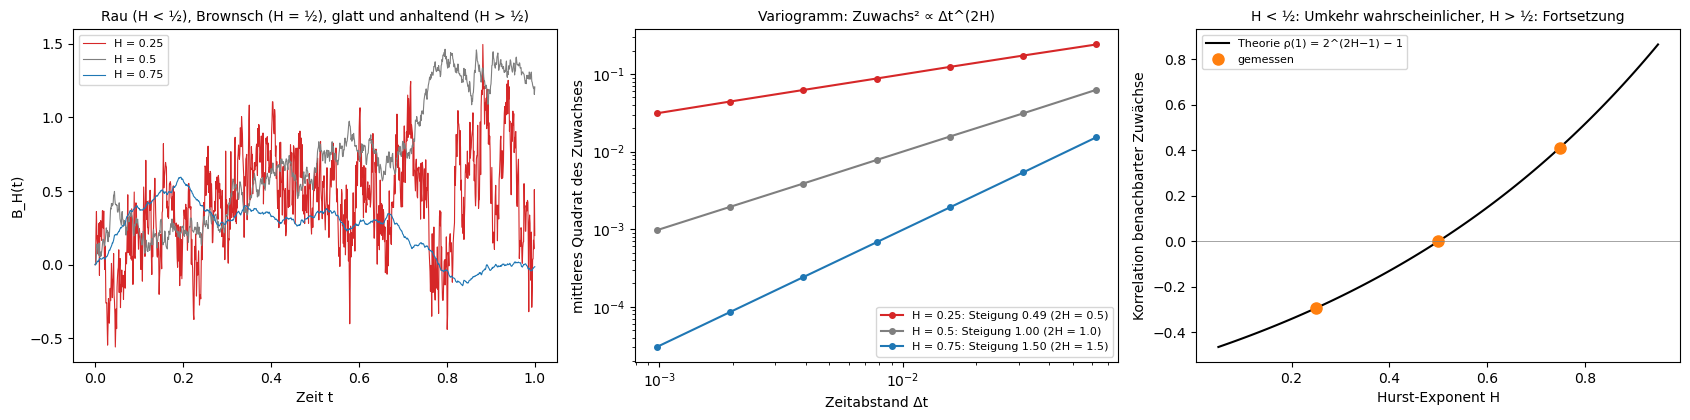

H = 0.25: geschätzt aus dem Variogramm 0.246;  Korrelation benachbarter Zuwächse -0.291 (Theorie -0.293)
H = 0.5: geschätzt aus dem Variogramm 0.501;  Korrelation benachbarter Zuwächse -0.000 (Theorie +0.000)
H = 0.75: geschätzt aus dem Variogramm 0.748;  Korrelation benachbarter Zuwächse +0.410 (Theorie +0.414)


In [12]:
rng = np.random.default_rng(11)
Hs = [0.25, 0.5, 0.75]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
estimates, rho1 = {}, {}
lags = np.array([1, 2, 4, 8, 16, 32, 64])
for H, c in zip(Hs, ["tab:red", "tab:grey", "tab:blue"]):
    t, Bh = fbm(H, 1024, T=1.0, n_paths=200, rng=rng)
    axes[0].plot(t, Bh[0], lw=0.8, c=c, label=f"H = {H}")
    var = [np.mean((Bh[:, L:] - Bh[:, :-L]) ** 2) for L in lags]
    slope = np.polyfit(np.log(lags), np.log(var), 1)[0]
    estimates[H] = slope / 2
    axes[1].loglog(lags / 1024, var, "o-", c=c, ms=4, label=f"H = {H}: Steigung {slope:.2f} (2H = {2 * H})")
    inc = np.diff(Bh, axis=1)
    rho1[H] = np.mean(inc[:, :-1] * inc[:, 1:]) / np.mean(inc ** 2)
axes[0].set_xlabel("Zeit t")
axes[0].set_ylabel("B_H(t)")
axes[0].set_title("Rau (H < ½), Brownsch (H = ½), glatt und anhaltend (H > ½)", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Zeitabstand Δt")
axes[1].set_ylabel("mittleres Quadrat des Zuwachses")
axes[1].set_title("Variogramm: Zuwachs² ∝ Δt^(2H)", fontsize=10)
axes[1].legend(fontsize=8)
hh = np.linspace(0.05, 0.95, 100)
axes[2].plot(hh, 2 ** (2 * hh - 1) - 1, "k-", label="Theorie ρ(1) = 2^(2H−1) − 1")
axes[2].plot(Hs, [rho1[H] for H in Hs], "o", ms=8, c="tab:orange", label="gemessen")
axes[2].axhline(0, color="grey", lw=0.5)
axes[2].set_xlabel("Hurst-Exponent H")
axes[2].set_ylabel("Korrelation benachbarter Zuwächse")
axes[2].set_title("H < ½: Umkehr wahrscheinlicher, H > ½: Fortsetzung", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

for H in Hs:
    print(f"H = {H}: geschätzt aus dem Variogramm {estimates[H]:.3f};  Korrelation benachbarter Zuwächse {rho1[H]:+.3f} (Theorie {2 ** (2 * H - 1) - 1:+.3f})")

* Im **linken Bild** zittert der Pfad mit $H = 0.25$ (rot) stark und wechselt ständig die Richtung; der mit $H = 0.75$ (blau) ist glatter und läuft in längeren Trends; $H = 0.5$ (grau) liegt dazwischen. Im **mittleren Bild** liegen die Variogramme auf Geraden mit den Steigungen 0.49, 1.00 und 1.50, also $2H$; laut **Ausgabe** sind die daraus geschätzten Hurst-Exponenten 0.246, 0.501 und 0.748.
* Das **rechte Bild** zeigt die Korrelation benachbarter Zuwächse auf der Theoriekurve: $-0.291$ (Theorie $-0.293$), $0.000$ und $+0.410$ (Theorie $+0.414$). Das beantwortet die Vorhersage: Bei $H = 0.75$ setzt sich ein Anstieg eher fort, bei $H = 0.25$ folgt eher ein Rückgang. Nur bei $H = \tfrac12$ sind die Zuwächse unkorreliert.
* **Wo sie vorkommt:** In der **Hydrologie** fand Hurst 1951 an den Pegelständen des Nils und vielen anderen Reihen $H\approx0.7$; lange Trockenperioden sind dadurch wahrscheinlicher, als unabhängige Jahre erwarten ließen, was für die Größe von Staudämmen entscheidend ist. Der **Internetverkehr** ist selbstähnlich mit $H > \tfrac12$ (Leland et al. 1994). In der Finanzmathematik ist die Volatilität „rau“ mit $H\approx0.1$ (Gatheral, Jaisson und Rosenbaum 2018). In der **Turbulenz** wachsen Geschwindigkeitsunterschiede wie $\ell^{1/3}$ (Kolmogorov 1941). Dazu kommen fraktale Landschaften in der Computergrafik, Oberflächenrauheit, Herzfrequenzvariabilität und Klimareihen.

##### *12. Lévy-Prozesse: Sprünge und schwere Ränder*

Wie sehen Prozesse aus, die springen dürfen, und wie häufig sind große Sprünge? Vorher vorhersagen: Man mittelt $10^6$ Cauchy-verteilte Zahlen. Liegt der Mittelwert nahe 0?

Links stehen drei Lévy-Prozesse auf $[0, 1]$ mit 5000 Schritten: eine Brownsche Bewegung, ein zusammengesetzter Poisson-Prozess (Rate 20, normalverteilte Sprunghöhen mit Standardabweichung 0.3) und ein Cauchy-Prozess ($\alpha = 1$). Die y-Achse ist zwischen $-1$ und $1$ linear und außerhalb logarithmisch, damit kleine Bewegungen und große Sprünge zugleich sichtbar sind. In der Mitte stehen 3000 Schritte in der Ebene, einmal als Gaußscher Random Walk (normalverteilte Schritte), einmal als Lévy-Flug mit $\alpha = 1.5$ (zufällige Richtung, stabile Schrittlänge). Rechts steht die Wahrscheinlichkeit $P(\vert X\vert > x)$ für $10^6$ normalverteilte und $10^6$ Cauchy-verteilte Zahlen, doppelt logarithmisch.

**Hintergrund & Fachbegriffe:**
- **Lévy-Prozess:** unabhängige, stationäre Zuwächse, Sprünge erlaubt.
- **Zusammengesetzter Poisson-Prozess:** springt zu den Zeitpunkten eines Poisson-Prozesses um zufällige Höhen und bleibt dazwischen konstant.
- **Stabile Verteilung** mit Index $\alpha$: Summen bleiben in derselben Familie; $\alpha = 2$ ist die Normalverteilung, $\alpha = 1$ die Cauchy-Verteilung.
- **Schwere Ränder** (heavy tails): $P(\vert X\vert > x)$ fällt nur wie eine Potenz $x^{-\alpha}$; im doppelt logarithmischen Plot eine Gerade.
- **Lévy-Flug:** ein Random Walk mit stabil verteilten Schrittlängen; viele kurze Schritte, selten sehr lange.

**Theorie:**

- **Brownsche Bewegung und Poisson-Prozess** sind die beiden Grundtypen: Die Brownsche Bewegung ist der einzige Lévy-Prozess mit stetigen Pfaden, der Poisson-Prozess der einfachste mit Sprüngen.
- **Lévy-Itô-Zerlegung:** Jeder Lévy-Prozess ist die Summe aus einer Drift, einer Brownschen Bewegung und einem Sprunganteil; die Sprünge mit Höhen in einem bestimmten Bereich kommen wie ein Poisson-Prozess. Die Rate der Sprünge jeder Größe heißt **Lévy-Maß**.
- **Stabile Prozesse** mit Index $\alpha\in(0, 2]$ sind selbstähnlich, $X(ct)$ ist verteilt wie $c^{1/\alpha}X(t)$; $\alpha = 2$ ist die Brownsche Bewegung. Für $\alpha < 2$ gilt $P(\vert X\vert > x)\propto x^{-\alpha}$; die Varianz ist unendlich, für $\alpha\leq1$ auch der Mittelwert. Nach dem verallgemeinerten zentralen Grenzwertsatz (Abschnitt 3 der Theorie) sind sie die Grenzwerte von Summen mit schweren Rändern.
- **Cauchy-Verteilung** ($\alpha = 1$): Dichte $1/(\pi(1 + x^2))$, also $P(\vert X\vert > x)\approx2/(\pi x)$ für großes $x$. Die Summe von $n$ Cauchy-Zahlen ist $n$-mal eine Cauchy-Zahl (Skalierung $n^{1/\alpha} = n$), ihr Mittelwert also wieder Cauchy-verteilt wie eine einzelne: Das Gesetz der großen Zahlen gilt nicht.
- **Lévy-Flug:** Der größte von $n$ stabil verteilten Schritten ist etwa $n^{1/\alpha}$ lang, bei normalverteilten Schritten nur etwa $\sqrt{2\ln n}$. Auch die Entfernung vom Start wächst wie $n^{1/\alpha}$, schneller als $\sqrt n$ beim Random Walk (**Superdiffusion**), und ein großer Teil davon geht auf wenige lange Sprünge zurück.

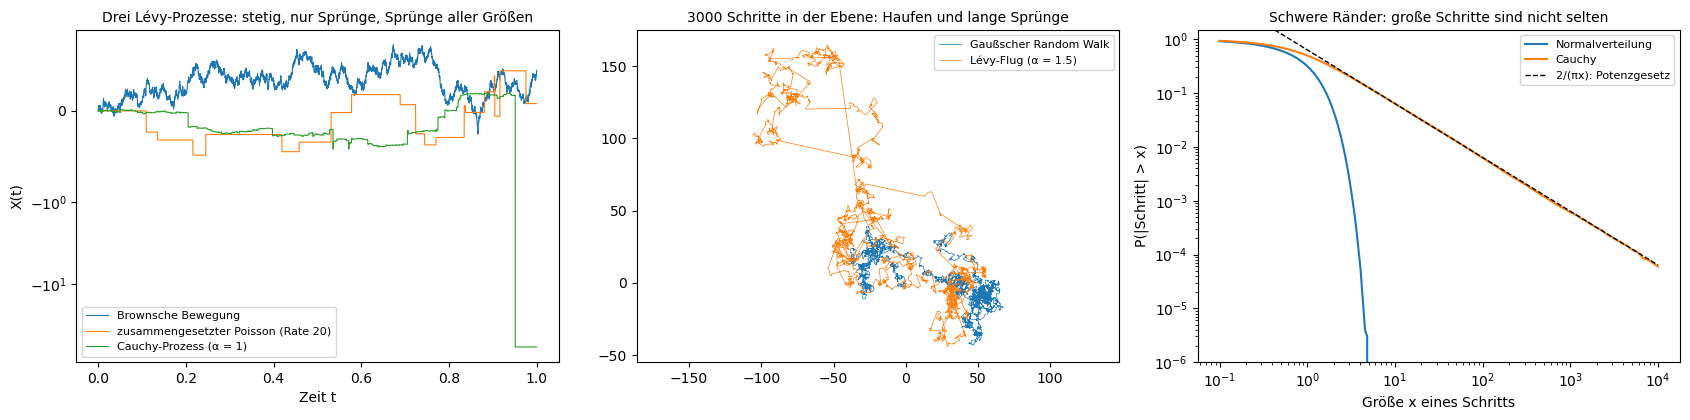

Brownsch: größter Einzelschritt / Summe der Beträge aller Schritte = 0.0009
Cauchy  : größter Einzelschritt / Summe der Beträge aller Schritte = 0.9304
Lévy-Flug: die 1 % längsten Schritte tragen 15% des Weges; beim Gaußschen Random Walk 3%
Cauchy: Mittelwert von 10^2, 10^4, 10^6 Werten: -1.30, -24.84, -2.60  (kein Gesetz der großen Zahl: der Mittelwert ist wieder Cauchy-verteilt)


In [13]:
rng = np.random.default_rng(12)
n = 5000
dt = 1.0 / n
gauss_inc = rng.normal(0, np.sqrt(dt), n)
cauchy_inc = stats.cauchy.rvs(scale=dt, size=n, random_state=rng)          # α = 1: Skala wächst wie dt^(1/α) = dt
jumps = rng.random(n) < 20 * dt                                           # zusammengesetzter Poisson-Prozess: Rate 20
cpp_inc = jumps * rng.normal(0, 0.3, n)                                  # Sprunghöhen normalverteilt

alpha = 1.5
steps2d = stats.levy_stable.rvs(alpha, 0, size=(3000, 2), random_state=rng)
angles = rng.uniform(0, 2 * np.pi, 3000)
lengths = np.abs(stats.levy_stable.rvs(alpha, 0, size=3000, random_state=rng))
levy_flight = np.cumsum(np.c_[lengths * np.cos(angles), lengths * np.sin(angles)], axis=0)
brown2d = np.cumsum(rng.normal(size=(3000, 2)), axis=0)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
tt = np.arange(1, n + 1) * dt
axes[0].plot(tt, np.cumsum(gauss_inc), lw=0.8, label="Brownsche Bewegung")
axes[0].plot(tt, np.cumsum(cpp_inc), lw=0.8, label="zusammengesetzter Poisson (Rate 20)")
axes[0].plot(tt, np.cumsum(cauchy_inc), lw=0.8, label="Cauchy-Prozess (α = 1)")
axes[0].set_yscale("symlog", linthresh=1)                        # linear zwischen −1 und 1, außerhalb logarithmisch
axes[0].set_xlabel("Zeit t")
axes[0].set_ylabel("X(t)")
axes[0].set_title("Drei Lévy-Prozesse: stetig, nur Sprünge, Sprünge aller Größen", fontsize=10)
axes[0].legend(fontsize=8)
axes[1].plot(brown2d[:, 0], brown2d[:, 1], lw=0.5, label="Gaußscher Random Walk")
axes[1].plot(levy_flight[:, 0], levy_flight[:, 1], lw=0.5, label=f"Lévy-Flug (α = {alpha})")
axes[1].set_aspect("equal", adjustable="datalim")
axes[1].set_title("3000 Schritte in der Ebene: Haufen und lange Sprünge", fontsize=10)
axes[1].legend(fontsize=8)
x = np.geomspace(0.1, 1e4, 200)
big_g = np.abs(rng.normal(size=10 ** 6)); big_c = np.abs(stats.cauchy.rvs(size=10 ** 6, random_state=rng))
axes[2].loglog(x, [np.mean(big_g > v) for v in x], label="Normalverteilung")
axes[2].loglog(x, [np.mean(big_c > v) for v in x], label="Cauchy")
axes[2].loglog(x, 2 / (np.pi * x), "k--", lw=1, label="2/(πx): Potenzgesetz")
axes[2].set_ylim(1e-6, 1.5)
axes[2].set_xlabel("Größe x eines Schritts")
axes[2].set_ylabel("P(|Schritt| > x)")
axes[2].set_title("Schwere Ränder: große Schritte sind nicht selten", fontsize=10)
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

for name, inc in [("Brownsch", gauss_inc), ("Cauchy", cauchy_inc)]:
    print(f"{name:8s}: größter Einzelschritt / Summe der Beträge aller Schritte = {np.abs(inc).max() / np.abs(inc).sum():.4f}")
lf = np.hypot(*np.diff(levy_flight, axis=0).T); bw = np.hypot(*np.diff(brown2d, axis=0).T)
print(f"Lévy-Flug: die 1 % längsten Schritte tragen {np.sort(lf)[-30:].sum() / lf.sum():.0%} des Weges; beim Gaußschen Random Walk {np.sort(bw)[-30:].sum() / bw.sum():.0%}")
print(f"Cauchy: Mittelwert von 10^2, 10^4, 10^6 Werten: " + ", ".join(f"{stats.cauchy.rvs(size=m, random_state=rng).mean():+.2f}" for m in (10 ** 2, 10 ** 4, 10 ** 6))
      + "  (kein Gesetz der großen Zahl: der Mittelwert ist wieder Cauchy-verteilt)")

* Im **linken Bild** wackelt die Brownsche Bewegung (blau) stetig; der zusammengesetzte Poisson-Prozess (orange) bleibt stückweise konstant und springt etwa 20-mal; der Cauchy-Prozess (grün) wackelt meist wenig, springt aber kurz vor $t = 1$ auf etwa $-59$, weiter als alle anderen Bewegungen zusammen. Laut **Ausgabe** ist beim Cauchy-Prozess der größte Einzelschritt 93 % der Summe aller Schrittbeträge, bei der Brownschen Bewegung 0.09 %.
* Im **mittleren Bild** bleibt der Gaußsche Random Walk in einem kompakten Knäuel. Der Lévy-Flug bildet Haufen, die durch lange Sprünge verbunden sind, und erkundet eine viel größere Fläche; seine 1 % längsten Schritte tragen 15 % des Weges (Gaußsch 3 %). Im **rechten Bild** fällt die Normalverteilung ab $x\approx3$ steil ab, über 5 kommt in $10^6$ Zahlen praktisch nichts vor. Die Cauchy-Verteilung fällt nur wie $2/(\pi x)$: Etwa jeder 1600. Wert ist größer als 1000. Antwort auf die Vorhersage: Die Mittelwerte von $10^2$, $10^4$ und $10^6$ Werten sind $-1.30$, $-24.84$ und $-2.60$; sie werden nicht kleiner, denn der Mittelwert ist wieder Cauchy-verteilt. Mehr Daten helfen nicht, solange man den Mittelwert benutzt.
* **Wo sie vorkommen:** Sprünge an **Finanzmärkten** (Merton-Sprungdiffusion, Varianz-Gamma- und CGMY-Modelle), Schadenssummen von Versicherungen, **anomale Diffusion** in Plasmen, Zellen und porösen Medien, Licht in „Lévy-Gläsern“, die Suche nach Nahrung (die Lévy-Flug-Hypothese für Albatrosse und Haie ist umstritten: Edwards et al. 2007 fanden in korrigierten Albatros-Daten keine Lévy-Flüge), Optimierungsverfahren mit Lévy-Schritten und das Rauschen des stochastischen Gradientenabstiegs, das in tiefen Netzen schwere Ränder zeigen kann (Şimşekli et al. 2019). Für schwere Ränder sind robuste Kennzahlen wie der Median nötig (Variation 7).

##### *13. Gauß-Prozesse: ein Kern bestimmt den Prozess*

Wie legt ein Kern das Aussehen von Zufallsfunktionen fest, und wie sagt ein Gauß-Prozess aus wenigen Punkten eine Funktion samt Unsicherheit voraus? Vorher vorhersagen: Wo wird die Unsicherheit der Vorhersage am größten sein?

Links steht je eine Zufallsfunktion aus drei Kernen auf 300 Punkten in $[0, 10]$, gezogen über die Cholesky-Zerlegung der Kernmatrix: RBF mit Längenskala 1, exponentiell (der Ornstein-Uhlenbeck-Prozess) und periodisch mit Periode 3. Mitte und rechts zeigen eine GP-Regression: Von der Funktion $\sin x + 0.1\,x\cos(1.5x)$ sind nur sechs Punkte mit Messrauschen der Standardabweichung 0.05 bekannt. Der Gauß-Prozess sagt Mittelwert und $\pm2$-Standardabweichungs-Band voraus, einmal mit RBF-Kern, einmal mit exponentiellem Kern. Die Ausgabe gibt die Unsicherheit an den Messpunkten und in der Lücke zwischen 3.5 und 5 sowie den größten Fehler innerhalb und außerhalb des Messbereichs.

**Hintergrund & Fachbegriffe:**
- **Kern** $k(x, x')$: die Kovarianz der Funktionswerte an zwei Stellen; er bestimmt Glattheit, Längenskala und Periodizität.
- **Längenskala** $\ell$: der Abstand, über den Funktionswerte noch stark korreliert sind.
- **A-priori-Verteilung:** die Verteilung der Funktionen vor den Daten (links). **A-posteriori-Verteilung:** nach den Daten (Mitte und rechts).
- **Messrauschen:** die Ungenauigkeit der Beobachtungen, hier $\sigma_n = 0.05$; es setzt eine Untergrenze für die Unsicherheit an den Messpunkten.
- **Hyperparameter:** Kernparameter wie $\ell$; hier fest gewählt, in der Praxis meist durch Maximieren der Randwahrscheinlichkeit (marginal likelihood) angepasst.

**Theorie:**

- **Definition:** $f\sim\mathcal{GP}(m, k)$ heißt: Für alle Punkte $x_1, \dots, x_n$ ist $(f(x_1), \dots, f(x_n))$ normalverteilt mit Mittelwerten $m(x_i)$ und Kovarianzmatrix $K_{ij} = k(x_i, x_j)$. Der Index muss keine Zeit sein; ein Gauß-Prozess ist eine Wahrscheinlichkeitsverteilung über Funktionen. Ein Kern muss **positiv semidefinit** sein, damit jede solche Matrix eine gültige Kovarianzmatrix ist.
- **Kerne:** RBF $e^{-(x - x')^2/2\ell^2}$ gibt beliebig oft differenzierbare Funktionen; exponentiell $e^{-\vert x - x'\vert/\ell}$ ist der Ornstein-Uhlenbeck-Prozess (Exp. 10), stetig, aber rau; periodisch $e^{-2\sin^2(\pi\vert x - x'\vert/p)/\ell^2}$ gibt Funktionen mit Periode $p$. Auch die Brownsche Bewegung ($\min(s, t)$) und die fBM sind Gauß-Prozesse. Ziehen kann man eine Funktion wie bei der fBM: $f = Lz$ mit $K = LL^T$.
- **GP-Regression:** Aus Messungen $y_i = f(x_i) + \varepsilon_i$ mit Rauschvarianz $\sigma_n^2$ folgt für einen neuen Punkt $x_\ast$ wieder eine Normalverteilung mit
$$\bar f_\ast = k_\ast^T(K + \sigma_n^2I)^{-1}y,\qquad\mathrm{Var}(f_\ast) = k(x_\ast, x_\ast) - k_\ast^T(K + \sigma_n^2I)^{-1}k_\ast ,$$
wobei $k_\ast$ der Vektor der Kovarianzen zwischen $x_\ast$ und den Messpunkten ist. Die Varianz ist klein, wo $x_\ast$ stark mit Messpunkten korreliert, und kehrt fern der Daten zur Varianz $k(x_\ast, x_\ast)$ des Prozesses zurück.

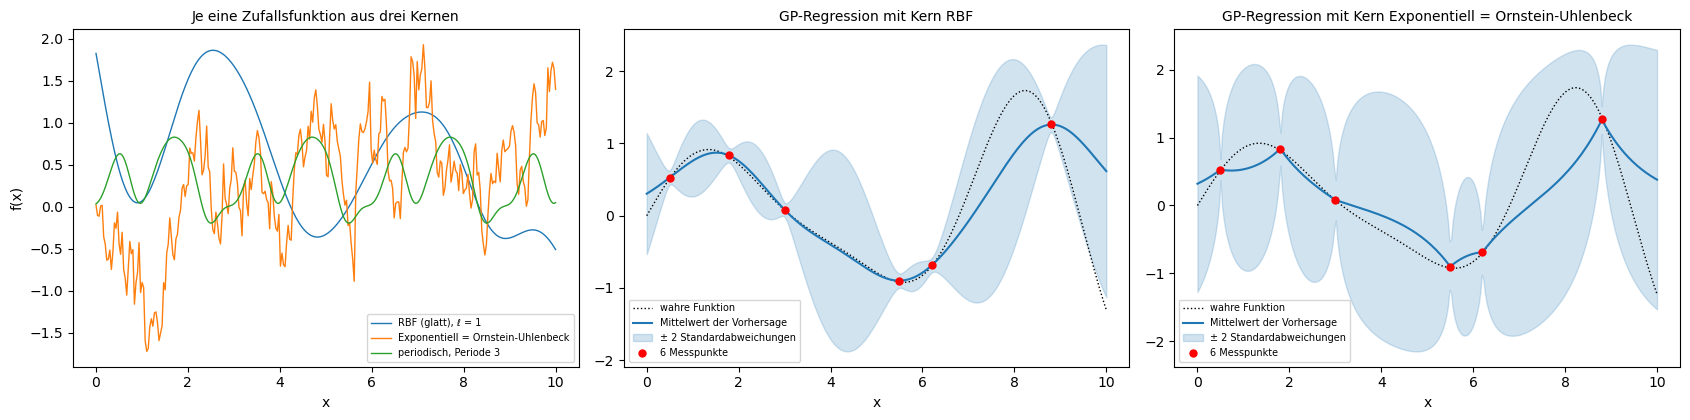

RBF (glatt), ℓ = 1                : Unsicherheit an den Messpunkten 0.050, in der Lücke 3.5 < x < 5 im Mittel 0.567; Fehler im Bereich der Messpunkte höchstens 0.82, jenseits von x = 8.8 bis 1.92
Exponentiell = Ornstein-Uhlenbeck : Unsicherheit an den Messpunkten 0.050, in der Lücke 3.5 < x < 5 im Mittel 0.882; Fehler im Bereich der Messpunkte höchstens 1.20, jenseits von x = 8.8 bis 1.68


In [14]:
rng = np.random.default_rng(13)
x = np.linspace(0, 10, 300)
kernels = {
    "RBF (glatt), ℓ = 1": lambda a, b: np.exp(-0.5 * (a[:, None] - b[None, :]) ** 2),
    "Exponentiell = Ornstein-Uhlenbeck": lambda a, b: np.exp(-np.abs(a[:, None] - b[None, :])),
    "periodisch, Periode 3": lambda a, b: np.exp(-2 * np.sin(np.pi * np.abs(a[:, None] - b[None, :]) / 3) ** 2),
}

def gp_posterior(xs, ys, xq, k, noise=0.05):
    """GP-Regression: Mittelwert und Standardabweichung an den Punkten xq nach den Beobachtungen (xs, ys)."""
    K = k(xs, xs) + noise ** 2 * np.eye(len(xs))
    Ks, Kss = k(xq, xs), k(xq, xq)
    Lc = np.linalg.cholesky(K)
    alpha = np.linalg.solve(Lc.T, np.linalg.solve(Lc, ys))
    v = np.linalg.solve(Lc, Ks.T)
    return Ks @ alpha, np.sqrt(np.clip(np.diag(Kss) - np.sum(v ** 2, axis=0), 0, None))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for (name, k), c in zip(kernels.items(), ["tab:blue", "tab:orange", "tab:green"]):
    L = np.linalg.cholesky(k(x, x) + 1e-8 * np.eye(len(x)))
    axes[0].plot(x, L @ rng.normal(size=len(x)), c=c, lw=1, label=name)
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")
axes[0].set_title("Je eine Zufallsfunktion aus drei Kernen", fontsize=10)
axes[0].legend(fontsize=7)
truth = lambda z: np.sin(z) + 0.3 * z * np.cos(1.5 * z) / 3
xs = np.array([0.5, 1.8, 3.0, 5.5, 6.2, 8.8])
ys = truth(xs) + rng.normal(0, 0.05, len(xs))
for ax, (name, k) in zip(axes[1:], list(kernels.items())[:2]):
    m, s = gp_posterior(xs, ys, x, k)
    ax.plot(x, truth(x), "k:", lw=1, label="wahre Funktion")
    ax.plot(x, m, c="tab:blue", label="Mittelwert der Vorhersage")
    ax.fill_between(x, m - 2 * s, m + 2 * s, color="tab:blue", alpha=0.2, label="± 2 Standardabweichungen")
    ax.plot(xs, ys, "ro", ms=5, label="6 Messpunkte")
    ax.set_xlabel("x")
    ax.set_title(f"GP-Regression mit Kern {name.split(',')[0].split(' (')[0]}", fontsize=10)
    ax.legend(fontsize=7, loc="lower left")
plt.tight_layout()
plt.show()

for name, k in list(kernels.items())[:2]:
    m, s = gp_posterior(xs, ys, x, k)
    gap = (x > 3.5) & (x < 5.0)
    inside = (x >= xs.min()) & (x <= xs.max())
    print(f"{name:34s}: Unsicherheit an den Messpunkten {gp_posterior(xs, ys, xs, k)[1].mean():.3f}, in der Lücke 3.5 < x < 5 im Mittel {s[gap].mean():.3f}; "
          f"Fehler im Bereich der Messpunkte höchstens {np.abs(m - truth(x))[inside].max():.2f}, jenseits von x = {xs.max()} bis {np.abs(m - truth(x))[~inside].max():.2f}")

* Im **linken Bild** ist die RBF-Funktion (blau) glatt, die exponentielle (orange) rau wie ein Ornstein-Uhlenbeck-Pfad, denn sie ist einer, und die periodische (grün) wiederholt sich alle 3 Einheiten. Alle drei haben Varianz 1; nur der Kern unterscheidet sie. Mit der Wahl des Kerns legt man fest, welche Funktionen man für plausibel hält.
* Im **mittleren Bild** (RBF) geht die Vorhersage durch die Messpunkte, das Band zieht sich dort auf die Messgenauigkeit zusammen (laut **Ausgabe** 0.050) und weitet sich in Lücken (im Mittel 0.567 zwischen 3.5 und 5) und ganz rechts außerhalb der Daten. Das ist die Antwort auf die Vorhersage. Im Messbereich liegt die wahre Funktion im Band, der größte Fehler ist 0.82 (zwischen 6.2 und 8.8, wo der wahre Hügel höher ist, als die Punkte verraten). Jenseits von 8.8 wächst der Fehler bis 1.92, und die wahre Funktion erreicht den Rand des Bandes: Extrapolation ist unsicher, und der GP sagt das auch.
* Im **rechten Bild** (exponentieller Kern) verbindet die Vorhersage die Punkte mit Knicken und fällt in Lücken schnell zum Mittelwert 0 zurück; das Band ist breiter (0.882 in der Lücke), der größte Fehler im Messbereich 1.20. Ein rauer Kern für eine glatte Funktion verschlechtert die Vorhersage: Die Wahl des Kerns ist die eigentliche Modellannahme. **Wo sie vorkommen:** **Bayes-Optimierung** (Hyperparameter-Suche für ML-Modelle, Planung teurer Experimente), **Kriging** in der Geostatistik (Lagerstätten, Bodenkarten), Ersatzmodelle (Surrogate) für teure Simulationen, Lichtkurven und Rauschmodelle in der Astronomie (Suche nach Exoplaneten), aktives Lernen und Robotik. Neuronale Netze mit unendlich vielen Neuronen pro Schicht sind Gauß-Prozesse (Neal 1996, Neural Tangent Kernel).

##### *14. Verzweigungsprozesse: Aussterben oder Explosion*

Stirbt eine Familie oder eine Epidemie aus, wenn jedes Mitglied im Mittel genau einen Nachkommen hat? Vorher vorhersagen: Wie wahrscheinlich ist das Aussterben bei $m = 1$, und wie wahrscheinlich bei $m = 1.5$, wo die Population im Mittel exponentiell wächst?

Simuliert wird der Galton-Watson-Prozess mit Poisson-verteilten Nachkommenzahlen, je 20 000 Stammbäume über 60 Generationen für $m = 0.8, 1.0, 1.2, 1.5, 2.0$ (Generationen über $10^6$ werden beim Ziehen gekappt, um Überläufe zu vermeiden; aussterben können sie praktisch nicht mehr). Links stehen 20 Stammbäume mit $m = 1$ (lineare Achse), in der Mitte 20 mit $m = 1.5$ (logarithmische Achse, × markiert ein Aussterben), rechts der Anteil noch lebender Stammbäume über die Generationen, mit $1 - q$ (gestrichelt), $0.8^n$ und $2/n$. Die Ausgabe vergleicht die Aussterbeanteile mit der Fixpunktgleichung $q = e^{m(q - 1)}$.

**Hintergrund & Fachbegriffe:**
- **Galton-Watson-Prozess:** Jedes Individuum hat unabhängig eine zufällige Zahl von Nachkommen; $Z_n$ ist die Größe der Generation $n$.
- **Reproduktionszahl** $m$: die mittlere Zahl der Nachkommen; in der Epidemiologie die **Basisreproduktionszahl** $R_0$.
- **Erzeugende Funktion** $G(s) = \mathbb E[s^{\text{Nachkommen}}]$; für die Poisson-Verteilung $e^{m(s - 1)}$.
- **Aussterbewahrscheinlichkeit** $q$: die kleinste Lösung von $q = G(q)$.
- **Unterkritisch, kritisch, überkritisch:** $m < 1$, $m = 1$, $m > 1$.

**Theorie:**

- **Mittelwert:** Jedes der $Z_n$ Individuen hat im Mittel $m$ Nachkommen, also $\mathbb E[Z_{n+1}\mid Z_n] = mZ_n$ und $\mathbb E[Z_n] = m^n$; $Z_n/m^n$ ist ein Martingal (Exp. 4).
- **Fixpunktgleichung:** Die Linie stirbt aus, wenn die Linien aller Kinder aussterben, jede unabhängig mit Wahrscheinlichkeit $q$. Bei $j$ Kindern ist das $q^j$, gemittelt über die Kinderzahl $G(q)$. Also ist $q = G(q)$, und die Aussterbewahrscheinlichkeit ist die kleinste Lösung in $[0, 1]$. Für Poisson-Nachkommen ist $G(s) = e^{m(s - 1)}$, für geometrische mit Mittelwert $m$ ist $G(s) = 1/(1 + m(1 - s))$ und $q = 1/m$ (Variation 6).
- **Drei Fälle:** **unterkritisch** ($m < 1$): sicheres Aussterben, die Überlebenswahrscheinlichkeit fällt wie $m^n$; **kritisch** ($m = 1$): ebenfalls sicheres Aussterben, obwohl der Mittelwert konstant 1 bleibt, die Überlebenswahrscheinlichkeit fällt nur wie $2/(\sigma^2n)$ mit der Varianz $\sigma^2$ der Nachkommenzahl (Kolmogorov; bei Poisson ist $\sigma^2 = 1$); **überkritisch** ($m > 1$): Mit Wahrscheinlichkeit $1 - q > 0$ wächst die Linie wie $m^n$ ohne Ende, sonst stirbt sie meist früh aus.

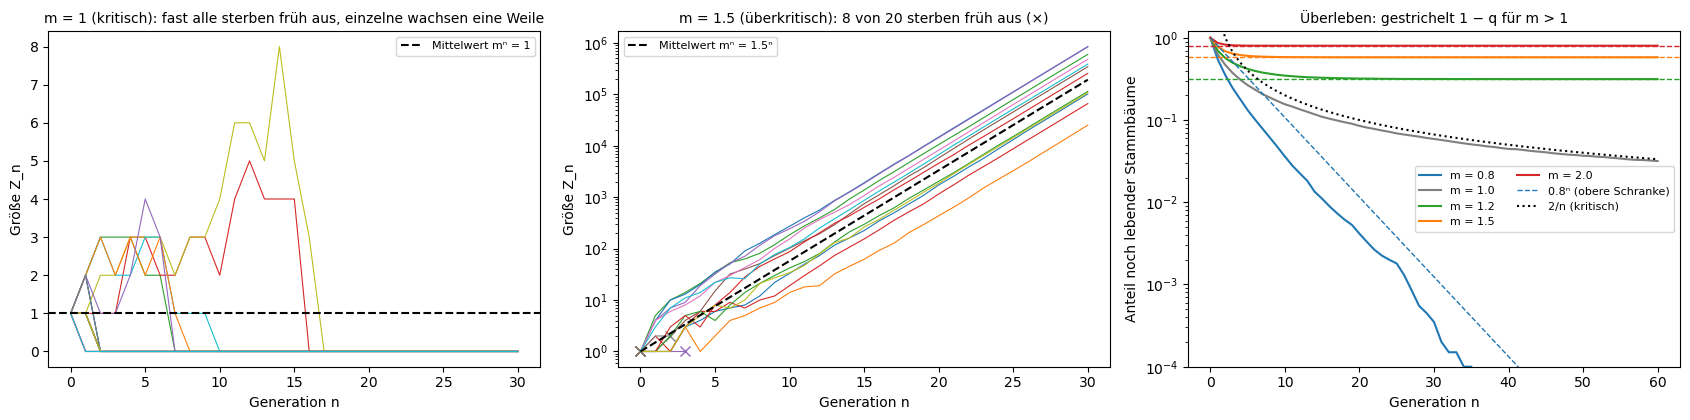

m = 0.8: ausgestorben nach 60 Generationen 1.000, Theorie q = 1.000
m = 1.0: ausgestorben nach 60 Generationen 0.968, Theorie q = 1.000
m = 1.2: ausgestorben nach 60 Generationen 0.685, Theorie q = 0.686
m = 1.5: ausgestorben nach 60 Generationen 0.419, Theorie q = 0.417
m = 2.0: ausgestorben nach 60 Generationen 0.199, Theorie q = 0.203
Kritisch (m = 1), Anteil lebender Stammbäume bei n = 10, 30, 60: 0.155 (2/n = 0.200), 0.059 (2/n = 0.067), 0.032 (2/n = 0.033)


In [15]:
rng = np.random.default_rng(14)

def galton_watson(m, generations, n_runs, rng, cap=10 ** 6):
    """Galton-Watson-Prozess: jedes Individuum hat Poisson(m) Nachkommen. Gibt die Größen Z_0 ... Z_g zurück."""
    Z = np.zeros((n_runs, generations + 1), dtype=np.int64); Z[:, 0] = 1
    for g in range(generations):
        z = np.minimum(Z[:, g], cap)
        Z[:, g + 1] = rng.poisson(m * z)                         # Summe von z unabhängigen Poisson(m) ist Poisson(m·z)
    return Z

def extinction_probability(m):
    """Kleinste Lösung von q = exp(m(q − 1)), der erzeugenden Funktion der Poisson-Verteilung."""
    q = 0.0
    for _ in range(10_000):
        q = np.exp(m * (q - 1))
    return q

ms = [0.8, 1.0, 1.2, 1.5, 2.0]
colors = ["tab:blue", "tab:grey", "tab:green", "tab:orange", "tab:red"]
runs = {m: galton_watson(m, 60, 20_000, rng) for m in ms}         # je 20 000 Stammbäume über 60 Generationen

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
n30 = np.arange(31)
for z in galton_watson(1.0, 30, 20, rng):
    axes[0].plot(n30, z, lw=0.8)
axes[0].axhline(1, color="k", ls="--", lw=1.5, label="Mittelwert mⁿ = 1")
axes[0].set_xlabel("Generation n")
axes[0].set_ylabel("Größe Z_n")
axes[0].set_title("m = 1 (kritisch): fast alle sterben früh aus, einzelne wachsen eine Weile", fontsize=10)
axes[0].legend(fontsize=8)
Z15 = galton_watson(1.5, 30, 20, rng)
for z in Z15:
    alive = z > 0
    line, = axes[1].semilogy(n30, np.where(alive, z, np.nan), lw=0.8)
    if not alive[-1]:
        g = np.argmax(~alive)                                    # erste Generation ohne Individuen
        axes[1].plot(g - 1, z[g - 1], "x", c=line.get_color(), ms=7)
axes[1].semilogy(n30, 1.5 ** n30, "k--", lw=1.5, label="Mittelwert mⁿ = 1.5ⁿ")
axes[1].set_xlabel("Generation n")
axes[1].set_ylabel("Größe Z_n")
axes[1].set_title(f"m = 1.5 (überkritisch): {np.sum(Z15[:, -1] == 0)} von 20 sterben früh aus (×)", fontsize=10)
axes[1].legend(fontsize=8)
gens = np.arange(61)
for m, c in zip(ms, colors):
    surv = (runs[m] > 0).mean(axis=0)
    axes[2].semilogy(gens, np.where(surv > 0, surv, np.nan), c=c, label=f"m = {m}")
    if m > 1:
        axes[2].axhline(1 - extinction_probability(m), color=c, ls="--", lw=1)
axes[2].semilogy(gens, 0.8 ** gens, c="tab:blue", ls="--", lw=1, label="0.8ⁿ (obere Schranke)")
axes[2].semilogy(gens[1:], 2 / gens[1:], "k:", lw=1.5, label="2/n (kritisch)")
axes[2].set_ylim(1e-4, 1.2)
axes[2].set_xlabel("Generation n")
axes[2].set_ylabel("Anteil noch lebender Stammbäume")
axes[2].set_title("Überleben: gestrichelt 1 − q für m > 1", fontsize=10)
axes[2].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

for m in ms:
    print(f"m = {m}: ausgestorben nach 60 Generationen {np.mean(runs[m][:, -1] == 0):.3f}, Theorie q = {extinction_probability(m):.3f}")
surv1 = (runs[1.0] > 0).mean(axis=0)
print("Kritisch (m = 1), Anteil lebender Stammbäume bei n = 10, 30, 60: " + ", ".join(f"{surv1[n]:.3f} (2/n = {2 / n:.3f})" for n in (10, 30, 60)))

* Im **linken Bild** sterben bei $m = 1$ die meisten Linien nach wenigen Generationen aus; einzelne wachsen eine Weile (bis 8), sterben aber ebenfalls. Der Mittelwert bleibt trotzdem 1, weil die wenigen großen Linien die vielen ausgestorbenen ausgleichen. Im **mittleren Bild** ($m = 1.5$) gibt es zwei Gruppen: Linien, die die ersten Generationen überstehen, wachsen parallel zur Geraden $1.5^n$; die übrigen, hier 8 von 20 (passend zu $q = 0.417$), sterben früh aus (×; viele Marken liegen übereinander, weil diese Linien schon in Generation 1 oder 2 enden). Dazwischen gibt es kaum etwas.
* Im **rechten Bild** fällt der Anteil lebender Stammbäume bei $m = 0.8$ parallel zu $0.8^n$, bei $m = 1$ nur langsam entlang $2/n$, und bei $m > 1$ erreicht er ein Plateau bei $1 - q$. Laut **Ausgabe** sind nach 60 Generationen ausgestorben: 1.000 ($m = 0.8$), 0.968 ($m = 1$; Theorie 1, die übrigen 3.2 % sterben später), 0.685 ($m = 1.2$, Theorie 0.686), 0.419 ($m = 1.5$, Theorie 0.417) und 0.199 ($m = 2$, Theorie 0.203). Bei $m = 1$ leben nach 10, 30 und 60 Generationen noch 0.155, 0.059 und 0.032 der Stammbäume, gegen $2/n = 0.200$, $0.067$, $0.033$; die Formel gilt für große $n$. Die Antwort auf die Vorhersage: Bei $m = 1$ stirbt jede Linie sicher aus, bei $m = 1.5$ immer noch 42 %, obwohl der Mittelwert exponentiell wächst.
* **Wo er vorkommt:** beim Aussterben von **Familiennamen** (die ursprüngliche Frage von Galton) und von Linien des Y-Chromosoms oder der mitochondrialen DNA, bei **Epidemien** (unter $R_0 = 1$ erlischt ein Ausbruch sicher, darüber kann er trotzdem früh erlöschen; große Unterschiede zwischen Infizierten, das **Superspreading**, erhöhen diese Wahrscheinlichkeit, Lloyd-Smith et al. 2005), bei der **Kettenreaktion** der Kernspaltung (ein Reaktor läuft genau kritisch), bei Zellteilung und Krebsentstehung, bei Kaskaden in sozialen Netzen (virale Beiträge) und Stromnetzen und bei Teilchenschauern in Detektoren und in der kosmischen Strahlung.

#### **Ergebnis**

Beim Lauf vom 2026-10-26:

- **Bernoulli-Prozess:** Erfolge binomialverteilt (Mittel 90.10, Varianz 64.60 gegen 90 und 63), Wartezeiten geometrisch und gedächtnislos: Nach drei Fehlversuchen ist die Wahrscheinlichkeit, noch zwei weitere zu brauchen, 0.489 wie am Anfang.
- **Random Walk:** Abstand vom Start wie $\sqrt n$ (Streuung 31.4 nach 1000 Schritten); 40.8 % der Pfade verbringen mehr als 90 % der Zeit auf einer Seite (Arkussinus 41.0 %); im Mittel nur 24.6 Rückkehren in 1000 Schritten.
- **Markov-Kette:** Die Wetterkette vergisst ihren Start wie $0.456^n$ und verbringt die Zeit nach der stationären Verteilung $(6/13, 4/13, 3/13)$; gemessen $(0.4635, 0.3056, 0.2309)$.
- **Martingale:** Bei allen sechs Stoppregeln gilt $P(+a) = b/(a + b)$ und mittlere Dauer $a\cdot b$; die Verdopplungsstrategie gewinnt in 99.89 % der Fälle 1 Euro und verliert in 0.11 % alles, der Erwartungswert bleibt 0.
- **Poisson-Prozess:** Varianz gleich Mittelwert (Fano-Faktor 1.013), Wartezeiten exponentiell, die Restwartezeit hängt nicht davon ab, wie lange man schon wartet.
- **Weißes Rauschen:** Autokorrelation null außer bei $\tau = 0$, flaches Spektrum bei 2; farbiges Rauschen gleicher Varianz verschiebt Leistung zu tiefen Frequenzen.
- **Brownsche Bewegung:** Varianz $t$, Kovarianz $\min(s, t)$; die Länge eines Pfads wächst ohne Grenze (203.5 bei $2^{16}$ Teilintervallen), die quadratische Variation bleibt bei 1 (0.993); Ausschnitte sehen gestreckt aus wie das Ganze.
- **Brownsche Brücke:** Varianz $t(1 - t)$ (0.2505 in der Mitte); die KS-Statistik folgt der Kolmogorov-Verteilung und überschreitet 1.358 in 4.9 % der Fälle.
- **Geometrische Brownsche Bewegung:** Nach 30 Jahren Median 211, Mittelwert 842; 79 % der Pfade liegen unter dem Mittelwert, 32.5 % unter dem Startwert, trotz 7 % erwarteter Rendite.
- **Ornstein-Uhlenbeck:** Rückkehr zum Mittelwert wie $e^{-\theta t}$, stationäre Varianz 0.485 (0.5), Autokorrelation $e^{-\theta\tau}$, Lorentz-Spektrum.
- **Gebrochene Brownsche Bewegung:** Das Variogramm liefert $H = 0.246, 0.501, 0.748$; benachbarte Zuwächse korrelieren mit $-0.291$, $0.000$, $+0.410$ wie $2^{2H - 1} - 1$.
- **Lévy-Prozesse:** Beim Cauchy-Prozess macht ein einziger Sprung 93 % der Bewegung aus; Cauchy-Mittelwerte konvergieren nicht ($-24.84$ bei $10^4$ Werten); beim Lévy-Flug tragen die längsten 1 % der Schritte 15 % des Weges.
- **Gauß-Prozesse:** Der Kern bestimmt das Aussehen der Funktionen; die GP-Regression gibt an den Messpunkten Unsicherheit 0.05, in Lücken 0.57 (RBF) und warnt bei Extrapolation selbst vor ihrem größten Fehler.
- **Verzweigungsprozesse:** Aussterbeanteile 0.685, 0.419 und 0.199 für $m = 1.2, 1.5, 2$ gegen die Fixpunkte 0.686, 0.417, 0.203; bei $m = 1$ stirbt jede Linie aus, die Überlebenden schrumpfen wie $2/n$.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Random Walk in drei Dimensionen:** Lass in Experiment 2 den Random Walk in drei Dimensionen laufen (in jedem Schritt eine zufällige Achse, Richtung $\pm1$) und miss den Anteil der Pfade, die in 10 000 Schritten mindestens einmal zum Start zurückkehren. *(Vorhersage: etwa 34 %, denn in drei Dimensionen kehrt ein Random Walk nur mit Wahrscheinlichkeit 0.34 je zurück (Pólya); in einer Dimension fast 99 %. Getestet: 33.7 % gegen 98.8 %.)*
2. **Anhaltender Regen:** Ändere in Experiment 3 die Regenzeile auf $(0.05, 0.05, 0.9)$. Wie lang werden Regenphasen, welchen Anteil der Tage regnet es, und wie schnell vergisst die Kette ihren Start? *(Vorhersage: Regenphasen 10 Tage, Regen an 63 % der Tage, $\vert\lambda_2\vert = 0.745$, nach zehn Tagen noch ein Abstand von 2 bis 4 % statt 0.02 %. Getestet mit den Eigenwerten und $\mu P^{10}$: 0.040, 0.018 und 0.019 für die drei Starts.)*
3. **Regelmäßigere Ereignisse:** Ersetze in Experiment 5 die exponentiellen Wartezeiten durch Gamma-verteilte mit Formparameter 4 und demselben Mittelwert 0.5. *(Vorhersage: Fano-Faktor etwa $1/4$, weil die Ereignisse regelmäßiger kommen. Getestet: 0.26.)*
4. **Mehr Volatilität:** Setze in Experiment 9 $\sigma = 0.5$. *(Vorhersage: Der Median fällt, weil $\mu - \sigma^2/2 = -0.055$ negativ ist, obwohl der Mittelwert weiter mit 7 % wächst; 73 % der Pfade enden unter 100, Median nach 30 Jahren etwa 19. Getestet: 72.6 %, Median 19.2.)*
5. **Euler-Verfahren mit großem Schritt:** Simuliere den OU-Prozess mit dem einfachen Euler-Verfahren $X_{k+1} = (1 - \theta\Delta t)X_k + \sigma\sqrt{\Delta t}\,Z_k$ und $\Delta t = 1.5$. *(Vorhersage: Der Prozess pendelt mit Autokorrelation $-0.5$ von Schritt zu Schritt, und seine Varianz ist $\sigma^2\Delta t/(1 - (1 - \theta\Delta t)^2) = 2$ statt 0.5; ab $\Delta t > 2$ explodiert er. Getestet: Varianz 2.01, Autokorrelation $-0.50$.)*
6. **Superspreading:** Ersetze in Experiment 14 die Poisson-Nachkommen durch geometrisch verteilte mit demselben Mittelwert $m = 1.5$ (größere Varianz). *(Vorhersage: Die Aussterbewahrscheinlichkeit steigt von 0.417 auf $1/m = 0.667$. Getestet: 0.663.)*
7. **Median statt Mittelwert:** Berechne in Experiment 12 den Median der Cauchy-Zahlen statt des Mittelwerts. *(Vorhersage: Er konvergiert gegen 0 mit Fehler etwa $\pi/(2\sqrt n)$, also 0.0016 bei $10^6$ Werten. Getestet: betragsmäßig unter 0.0001.)*
8. **Roulette:** Spiele die Verdopplungsstrategie aus Experiment 4 mit Gewinnwahrscheinlichkeit $18/37$ statt $\tfrac12$. *(Vorhersage: Der Erwartungswert wird negativ, etwa $-0.31$ Euro pro Spieler, obwohl immer noch 99.87 % gewinnen. Nachgerechnet: $0.9987\cdot1 - 0.0013\cdot1023$.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist ein stochastischer Prozess, und was ist ein Pfad?</summary>

Eine Familie von Zufallsvariablen $X_t$, eine für jeden Zeitpunkt. Ein Pfad ist der Verlauf $t\mapsto X_t$ bei einer bestimmten Ziehung des Zufalls; das Ensemble sind alle Pfade mit ihren Wahrscheinlichkeiten.
</details>

<details><summary>2. Was bedeuten Markov-Eigenschaft und Martingal-Eigenschaft, und ist das dasselbe?</summary>

Markov: Die Zukunft hängt nur vom heutigen Zustand ab, nicht vom Weg dorthin. Martingal: Die beste Vorhersage für morgen ist der heutige Wert (faires Spiel). Verschieden: Die Wetterkette ist Markovsch, aber kein Martingal; die gebrochene Brownsche Bewegung mit $H\neq\tfrac12$ ist keines von beiden; die Brownsche Bewegung ist beides.
</details>

<details><summary>3. Warum wächst der Abstand eines Random Walks vom Start wie die Wurzel der Schrittzahl?</summary>

Weil sich bei unabhängigen Schritten die Varianzen addieren: Nach $n$ Schritten der Größe 1 ist die Varianz $n$, die typische Entfernung also $\sqrt n$. Die Schritte heben sich zum großen Teil gegenseitig auf.
</details>

<details><summary>4. Was sagt das Arkussinus-Gesetz, und was folgt daraus für Führungen in einem fairen Spiel?</summary>

Der Zeitanteil, den ein Random Walk über null verbringt, hat eine U-förmige Dichte: Am wahrscheinlichsten liegt fast immer dieselbe Seite vorn, ein ausgeglichenes Verhältnis ist am seltensten. Lange Führungen sind also kein Zeichen von Können.
</details>

<details><summary>5. Wie findet man die stationäre Verteilung einer Markov-Kette, und was bestimmt, wie schnell die Kette sie erreicht?</summary>

Als linken Eigenvektor der Übergangsmatrix zum Eigenwert 1, $\pi P = \pi$, normiert auf Summe 1. Der Abstand fällt wie $\vert\lambda_2\vert^n$ mit dem betragsmäßig zweitgrößten Eigenwert; je größer die Spektrallücke $1 - \vert\lambda_2\vert$, desto schneller.
</details>

<details><summary>6. Was besagt der optionale Stoppsatz, und warum scheint die Verdopplungsstrategie ihn zu verletzen?</summary>

Bei einem fairen Spiel bleibt der erwartete Gewinn zur Stoppzeit 0, wenn der Spielstand bis dahin beschränkt bleibt. Die Verdopplung erfüllt diese Bedingung nur mit unbegrenztem Kapital nicht; mit begrenztem Kapital gewinnt man oft wenig und verliert selten alles, der Erwartungswert bleibt 0.
</details>

<details><summary>7. Mit welcher Wahrscheinlichkeit erreicht ein fairer Random Walk +a vor −b, und wie lange dauert das im Mittel?</summary>

$b/(a + b)$, aus dem Stoppsatz für $S_n$; im Mittel $a\cdot b$ Schritte, aus dem Stoppsatz für das Martingal $S_n^2 - n$.
</details>

<details><summary>8. Welche drei gleichwertigen Beschreibungen des Poisson-Prozesses gibt es?</summary>

Unabhängige, stationäre Zuwächse mit Poisson-verteilten Zählungen (Mittel und Varianz $\lambda t$); unabhängige exponentialverteilte Wartezeiten mit Mittel $1/\lambda$; Grenzfall eines Bernoulli-Prozesses mit $p = \lambda\,\Delta t$ in sehr kurzen Zeitschritten.
</details>

<details><summary>9. Warum wartet man bei rein zufällig fahrenden Bussen im Mittel den vollen Abstand und nicht die Hälfte?</summary>

Weil die exponentielle Wartezeit gedächtnislos ist: Egal wann man ankommt, die Restwartezeit hat wieder Mittelwert $1/\lambda$. Anschaulich landet man eher in einer langen Lücke als in einer kurzen (Wartezeit-Paradoxon).
</details>

<details><summary>10. Woran erkennt man weißes Rauschen, und wie hängen Autokorrelation und Spektrum zusammen?</summary>

Autokorrelation 0 bei jeder Verschiebung außer 0, flaches Leistungsspektrum. Das Spektrum ist die Fourier-Transformierte der Autokovarianz (Wiener-Chintschin); ein einzelner Strich bei $\tau = 0$ ergibt ein flaches Spektrum, eine langsam abfallende Korrelation ein Spektrum mit viel Leistung bei tiefen Frequenzen.
</details>

<details><summary>11. Warum ist ein Pfad der Brownschen Bewegung unendlich lang, und welche Summe bleibt endlich?</summary>

Über ein Intervall $\Delta t$ ändert sich $W$ um etwa $\sqrt{\Delta t}$; bei $n$ Intervallen ist die Summe der Beträge etwa $n\sqrt{1/n} = \sqrt n\to\infty$. Die Summe der Quadrate ist dagegen $n\cdot1/n = 1$, allgemein $t$ (quadratische Variation), daher $(\mathrm dW)^2 = \mathrm dt$.
</details>

<details><summary>12. Was ist eine Brownsche Brücke, und wo steckt sie in der Statistik?</summary>

Eine Brownsche Bewegung auf $[0, 1]$, die bei 0 enden muss, $B(t) = W(t) - tW(1)$, Varianz $t(1 - t)$. Die Abweichung $\sqrt n(F_n - F)$ der empirischen von der wahren Verteilungsfunktion wird für große $n$ zur Brücke; ihr Maximum ist die Statistik des Kolmogorov-Smirnov-Tests.
</details>

<details><summary>13. Warum liegt der Median einer geometrischen Brownschen Bewegung unter ihrem Mittelwert, und welche Wachstumsrate erlebt ein typischer Pfad?</summary>

Die Verteilung ist log-normal mit langem rechten Rand; wenige sehr große Werte ziehen den Mittelwert hoch. Der Mittelwert wächst mit $\mu$, der Median mit $\mu - \sigma^2/2$; diese kleinere Rate erlebt ein typischer Pfad.
</details>

<details><summary>14. Welche drei Eigenschaften hat der Ornstein-Uhlenbeck-Prozess, und wie sieht sein Spektrum aus?</summary>

Er ist stationär, Gaußsch und Markovsch (als einziger bis auf Skalierung); er kehrt zum Mittelwert zurück wie $e^{-\theta t}$, mit stationärer Varianz $\sigma^2/(2\theta)$ und Autokorrelation $e^{-\theta\tau}$. Sein Spektrum ist eine Lorentz-Kurve: flach unterhalb $\theta/2\pi$, darüber $\propto1/f^2$.
</details>

<details><summary>15. Was misst der Hurst-Exponent, und wie schätzt man ihn aus Daten?</summary>

Die Korrelation der Zuwächse: $H > \tfrac12$ persistent (Trends setzen sich fort), $H < \tfrac12$ antipersistent, $H = \tfrac12$ unkorreliert. Man trägt das mittlere Quadrat der Zuwächse gegen den Zeitabstand doppelt logarithmisch auf; die Steigung ist $2H$.
</details>

<details><summary>16. Was unterscheidet einen Cauchy-Prozess von der Brownschen Bewegung, und warum hilft Mitteln bei Cauchy-Daten nicht?</summary>

Er hat Sprünge und schwere Ränder, $P(\vert X\vert > x)\approx2/(\pi x)$, einzelne Sprünge dominieren die ganze Bewegung. Varianz und Mittelwert existieren nicht; der Mittelwert von $n$ Cauchy-Zahlen ist wieder Cauchy-verteilt wie eine einzelne Zahl. Der Median konvergiert dagegen.
</details>

<details><summary>17. Was legt der Kern eines Gauß-Prozesses fest, und was liefert die GP-Regression außer einer Vorhersage?</summary>

Die Kovarianz der Funktionswerte an zwei Stellen und damit Glattheit, Längenskala und Periodizität der Funktionen. Die Regression liefert zu jedem Punkt auch eine Standardabweichung: klein an den Messpunkten, groß in Lücken und außerhalb der Daten.
</details>

<details><summary>18. Wann stirbt ein Galton-Watson-Prozess sicher aus, und wie berechnet man sonst die Aussterbewahrscheinlichkeit?</summary>

Sicher, wenn die mittlere Nachkommenzahl $m\leq1$ ist (außer wenn jedes Individuum genau einen Nachkommen hat), auch bei $m = 1$, obwohl der Mittelwert konstant bleibt. Für $m > 1$ ist $q$ die kleinste Lösung von $q = G(q)$ mit der erzeugenden Funktion $G$; bei Poisson-Nachkommen $q = e^{m(q - 1)}$, für $m = 1.5$ also 0.417.
</details>

#### **Nächste Schritte**

- **Itô-Kalkül und stochastische Differentialgleichungen:** Itô-Integral, Itôs Lemma, das Euler-Maruyama- und das Milstein-Verfahren, und warum die Black-Scholes-Gleichung eine Wärmeleitungsgleichung ist.
- **Fokker-Planck-Gleichung:** die Gleichung für die Dichte eines Diffusionsprozesses; für den OU-Prozess eine Gleichung mit Normalverteilung als Gleichgewicht.
- **Diffusionsmodelle in der KI:** Ein Bild wird durch einen OU-artigen Prozess in Rauschen verwandelt; ein Netz lernt den rückwärts laufenden Prozess (Score-basierte SDEs).
- **MCMC:** Metropolis-Hastings und Langevin-Verfahren als Markov-Ketten mit vorgegebener stationärer Verteilung; Mischzeit und Spektrallücke in der Praxis.
- **Warteschlangen:** das M/M/1-Modell aus Poisson-Ankünften und exponentiellen Bedienzeiten, Wartezeiten bei hoher Auslastung.
- **Punktprozesse mit Selbstanregung:** Hawkes-Prozesse für Nachbeben, Börsenaufträge und Wellen in sozialen Netzen.
- **Netzwerke:** Random Walks und Epidemien auf Graphen (Notebook `complexnetworks.ipynb`).

#### **Referenzen**

- Durrett, R. (2019): *Probability: Theory and Examples*, 5th ed., Cambridge University Press.
- Feller, W. (1968): *An Introduction to Probability Theory and Its Applications*, Vol. 1, 3rd ed., Wiley.
- Grimmett, G. & Stirzaker, D. (2020): *Probability and Random Processes*, 4th ed., Oxford University Press.
- Norris, J. R. (1997): *Markov Chains*, Cambridge University Press.
- Øksendal, B. (2003): *Stochastic Differential Equations*, 6th ed., Springer.
- Mörters, P. & Peres, Y. (2010): *Brownian Motion*, Cambridge University Press.
- Rasmussen, C. E. & Williams, C. K. I. (2006): *Gaussian Processes for Machine Learning*, MIT Press.
- Levin, D. A., Peres, Y. & Wilmer, E. L. (2017): *Markov Chains and Mixing Times*, 2nd ed., American Mathematical Society.
- Mandelbrot, B. B. & Van Ness, J. W. (1968): *Fractional Brownian motions, fractional noises and applications*, SIAM Review 10, 422.
- Einstein, A. (1905): *Über die von der molekularkinetischen Theorie der Wärme geforderte Bewegung von in ruhenden Flüssigkeiten suspendierten Teilchen*, Annalen der Physik 17, 549.
- Uhlenbeck, G. E. & Ornstein, L. S. (1930): *On the Theory of the Brownian Motion*, Physical Review 36, 823.
- Lloyd-Smith, J. O., Schreiber, S. J., Kopp, P. E. & Getz, W. M. (2005): *Superspreading and the effect of individual variation on disease emergence*, Nature 438, 355.